# Credit Card Default Risk Analysis and Prediction

## Project Overview

### 1. Business Problem

Credit card default represents a significant financial risk for banks and credit card providers. Identifying customers who may default on their next monthly payment can help financial institutions reduce potential losses and improve risk monitoring.

This project combines **Data Science, Machine Learning** to analyze customer financial behavior, predict credit card default, and support data-driven decision-making.

A complementary Data Engineering workstream is planned to support data collection, storage, querying, and API integration.

### 2. Project Objective

**To support banks in identifying customers at risk of credit card default and improving credit risk management through early risk detection.**

To achieve this objective, the project focuses on:

- **Machine Learning:** Explore customer data, develop classification models, evaluate performance, and interpret predictions using Feature Importance and SHAP.
- **Data Engineering:** Collect, organize, store, and analyze data using CSV files, external APIs, web scraping, MySQL, SQL, BigQuery, and Flask API.

### 3. Dataset Description

The project uses the **Default of Credit Card Clients** dataset from the UCI Machine Learning Repository.

- **Records:** 30,000 customers
- **Original Columns:** 25 (including ID and target)
- **Target:** `default_next_month` (0 = No Default, 1 = Default)
- **Features:** Credit limits, demographic information, repayment history, bill statements, and payment amounts.
- **Prediction Task:** Binary Classification

### 4. Project Workflow

The project is organized into two main parts.

#### Part A — Data Science & Machine Learning

- **Step 0:** Data Loading and Initial Inspection
- **Step 1:** Data Cleaning and Validation
- **Step 2:** Exploratory Data Analysis (EDA)
- **Step 3:** Data Preprocessing and Feature Engineering
- **Step 4:** Classification Models, Hyperparameter Tuning, and Class Imbalance Handling
- **Step 5:** Final Model Evaluation, Explainability and ML Conclusion
- **Step 6:** Business Impact Analysis
- **Step 7:** Future Work
- **Step 8:** Final Project Conclusion

#### Part B — Data Engineering (Planned)

- **DE Step 1:** Data Collection — CSV, External API, Web Scraping
- **DE Step 2:** MySQL Database Design and ERD
- **DE Step 3:** Data Preparation and Database Integration
- **DE Step 4:** SQL Business Analysis
- **DE Step 5:** BigQuery Integration
- **DE Step 6:** Flask API Development
- **DE Step 7:** Documentation and Deliverables

### 5. Project Scope

The **Machine Learning** part covers data preparation, model training, hyperparameter tuning, evaluation, and SHAP explainability.

The **Data Engineering** part will focus on data collection, relational database management, SQL analysis, cloud-based data processing, and API development.

**Notebook Scope:** This notebook documents the Machine Learning workstream. Data Engineering components will be developed and documented separately.

**Data Source:** [UCI Machine Learning Repository — Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

## STEP 0 — Data Loading and Initial Inspection

We first inspect the file's structure and quality before making any changes.

In [1]:
# Step 0.1 - Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 1

In [2]:
# Step 0.2 - Load the CSV file
df = pd.read_csv("credit_card_default_clean.csv")

# Display the first five rows
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
# Step 0.3 - Check dataset dimensions
df.shape

(30000, 25)

**Observation:** The source CSV has **30,000 rows and 25 columns**. Each row represents one credit card client record.

In [4]:
# Step 0.4 - Inspect column names
df.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default payment next month']

In [5]:
# Step 0.5 - Inspect data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

**Observation:** All 25 fields are recorded as integers. However, integer storage does **not** mean every column is continuous: `SEX`, `EDUCATION`, `MARRIAGE` and repayment-status fields contain category/code values.

In [6]:
# Step 0.6 - Check missing values
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
missing_summary

,missing_count,missing_percent
ID,0,0.0
LIMIT_BAL,0,0.0
SEX,0,0.0
EDUCATION,0,0.0
MARRIAGE,0,0.0
AGE,0,0.0
PAY_0,0,0.0
PAY_2,0,0.0
PAY_3,0,0.0
PAY_4,0,0.0


**Observation:** No standard missing values (`NaN`) are found in this CSV. Some *category codes* still need validation; a zero or unusual code is not automatically a missing pandas value.

In [7]:
# Step 0.7 - Check full-row duplicates and duplicate IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Missing IDs:", df["ID"].isna().sum())

Duplicate rows: 0
Duplicate IDs: 0
Missing IDs: 0


**Observation:** There are **0 duplicate rows** and **0 duplicate IDs**. We keep all 30,000 observations; removing similar customer profiles would be inappropriate when their IDs differ.

In [8]:
# Step 0.8 - Display descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [9]:
# Step 0.9 - Inspect unique values per column
df.nunique().sort_values()

default payment next month        2
SEX                               2
MARRIAGE                          4
EDUCATION                         7
PAY_5                            10
PAY_6                            10
PAY_0                            11
PAY_2                            11
PAY_3                            11
PAY_4                            11
AGE                              56
LIMIT_BAL                        81
PAY_AMT5                       6897
PAY_AMT4                       6937
PAY_AMT6                       6939
PAY_AMT3                       7518
PAY_AMT2                       7899
PAY_AMT1                       7943
BILL_AMT6                     20604
BILL_AMT5                     21010
BILL_AMT4                     21548
BILL_AMT3                     22026
BILL_AMT2                     22346
BILL_AMT1                     22723
ID                            30000
dtype: int64

### 0.10 Understand the Data Dictionary

| Column(s) | Meaning | Data role |
|---|---|---|
| `ID` | Client record identifier | Identifier (exclude from ML) |
| `LIMIT_BAL` | Credit limit | Numerical |
| `SEX` | Sex code (1 / 2) | Categorical |
| `EDUCATION` | Education code | Categorical |
| `MARRIAGE` | Marital-status code | Categorical |
| `AGE` | Age in years | Numerical |
| `PAY_0`, `PAY_2`–`PAY_6` | Previous monthly repayment-status codes | Ordinal / special codes |
| `BILL_AMT1`–`BILL_AMT6` | Previous monthly statement amounts | Numerical |
| `PAY_AMT1`–`PAY_AMT6` | Previous payment amounts | Numerical |
| `default payment next month` | Default next month: 0 / 1 | **Target** |

**Important:** `PAY_0` is the original dataset's column name and refers to the most recent repayment-status month; it is **not** the target. Some repayment codes have special meanings. Do not treat negative status codes as invalid monetary values.

### 0.11 Inspect the Target Variable

In [10]:
# Step 0.11 - Count each target class
target_col = "default payment next month"
df[target_col].value_counts().sort_index()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [11]:
# Step 0.12 - Calculate target percentages
target_distribution = pd.DataFrame({
    "count": df[target_col].value_counts().sort_index(),
    "percentage": (df[target_col].value_counts(normalize=True).sort_index() * 100).round(2)
})
target_distribution.index.name = "default_next_month"
target_distribution

,count,percentage
default_next_month,,
0,23364,77.88
1,6636,22.12


**Observation:** The target is **binary**: 23,364 clients (**77.88%**) are in class `0` (No Default) and 6,636 (**22.12%**) are in class `1` (Default). The data is **moderately imbalanced**. In later modeling, overall accuracy should be compared with the **77.88% majority-class baseline**, and minority-class recall/F1 should also be evaluated.

---

## STEP 1 — Data Cleaning and Validation

### 1.1 Cleaning Strategy
We make only changes supported by data checks. We do **not** remove records merely because there are negative bill amounts or unusual repayment-status codes. We also do not apply SMOTE during cleaning; class imbalance will be handled *after* train/test splitting.

In [12]:
# Step 1.1 - Create a working copy
df = df.copy()

# Check the starting size
print("Starting shape:", df.shape)

Starting shape: (30000, 25)


### 1.2 Standardize the Target Column Name

Rename the target to a shorter, consistent English name while retaining its original 0/1 labels.

In [13]:
# Step 1.2 - Rename the target column
df = df.rename(columns={
    "default payment next month": "default_next_month"
})

df.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default_next_month']

**Observation:** Only the target **name** changes. Its values stay the same; this makes model code easier to read.

### 1.3 Validate the Binary Target

In [14]:
# Step 1.3 - Verify valid target labels
print("Target values:", sorted(df["default_next_month"].dropna().unique().tolist()))
print("Missing target:", df["default_next_month"].isna().sum())

assert df["default_next_month"].notna().all()
assert set(df["default_next_month"].unique()) == {0, 1}

Target values: [0, 1]
Missing target: 0


**Observation:** All records have a target value and both expected classes (`0` and `1`) are present. No target records need to be removed.

### 1.4 Inspect Categorical Codes

The official documentation defines core category meanings, but some additional/unusual codes occur in this file. We preserve them at this stage rather than silently inventing their meaning.

In [15]:
# Step 1.4 - Review demographics code frequencies
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())


SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


**Observation:**
- `SEX` has the expected codes `1` and `2`.
- `EDUCATION` includes `0`, `5` and `6` in addition to `1`–`4`. Their precise meaning is not established by this cleaned file, so they are **flagged but retained**.
- `MARRIAGE` contains code `0` (54 rows), beyond the common `1`–`3` categories. It is **flagged but retained**.

Treat these as **categorical codes** in later preprocessing, rather than imposing numeric distances between groups.

In [16]:
# Step 1.5 - Count special demographic codes
code_review = pd.DataFrame({
    "check": ["EDUCATION outside 1-4", "MARRIAGE outside 1-3"],
    "rows": [
        (~df["EDUCATION"].isin([1, 2, 3, 4])).sum(),
        (~df["MARRIAGE"].isin([1, 2, 3])).sum()
    ]
})
code_review

,check,rows
0,EDUCATION outside 1-4,345
1,MARRIAGE outside 1-3,54


### 1.6 Inspect Repayment Status Codes

`PAY_0`, `PAY_2`–`PAY_6` are **status codes**, not money amounts. Negative codes can be legitimate special repayment-status categories; do not drop them based on being negative.

In [17]:
# Step 1.6 - Check values used in repayment-status columns
pay_status_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

for col in pay_status_cols:
    print(col, sorted(df[col].unique().tolist()))

PAY_0 [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
PAY_2 [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
PAY_3 [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
PAY_4 [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
PAY_5 [-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]
PAY_6 [-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]


**Observation:** Repayment fields contain codes such as `-2`, `-1`, `0`, and positive delinquency codes. They are retained as recorded; a separate categorical or ordinal encoding decision will be made in the ML preprocessing stage.

### 1.7 Validate Numerical Fields

Check invalid credit limits, age ranges, bill balances and payment amounts. A negative **bill amount** may represent a credit balance and is not automatically a bad record.

In [18]:
# Step 1.7 - Basic numerical validation
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

validation = pd.Series({
    "non_positive_credit_limits": (df["LIMIT_BAL"] <= 0).sum(),
    "ages_below_18": (df["AGE"] < 18).sum(),
    "negative_bill_amounts": (df[bill_cols] < 0).sum().sum(),
    "negative_payment_amounts": (df[payment_cols] < 0).sum().sum()
}, name="count")
validation

non_positive_credit_limits       0
ages_below_18                    0
negative_bill_amounts         3932
negative_payment_amounts         0
Name: count, dtype: int64

**Observation:** No non-positive credit limits, ages below 18, or negative payment amounts were found. **Negative bill amounts do occur** and are retained because they may indicate credits/overpayments; removing them would require additional business validation. All observed ages range from **21 to 79**.

### 1.8 Final Missing-Value and Duplicate Checks

In [19]:
# Step 1.8 - Confirm data quality after cleaning
quality_check = pd.DataFrame({
    "check": ["Rows", "Columns", "Missing values", "Duplicate rows", "Duplicate IDs"],
    "result": [
        df.shape[0],
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["ID"].duplicated().sum())
    ]
})
quality_check

,check,result
0,Rows,30000
1,Columns,25
2,Missing values,0
3,Duplicate rows,0
4,Duplicate IDs,0


**Observation:** The cleaned table still has **30,000 rows and 25 columns**. No rows have been removed. The main cleaning decision is to standardize the target name, validate data quality, and explicitly document category-code anomalies rather than guessing replacements.

## Data Cleaning Summary

| Check | Result | Action |
|---|---|---|
| Dataset dimensions | 30,000 rows × 25 columns | Keep all observations |
| Missing values | 0 | No imputation needed |
| Duplicate rows / IDs | 0 / 0 | No duplicates removed |
| Binary target | 0: 77.88%; 1: 22.12% | Retain original labels |
| Target name | Contains spaces | Rename to `default_next_month` |
| Education / marriage codes | Additional special codes | Flag; do not invent mappings |
| Repayment status | Negative and positive codes | Preserve as status codes |
| Bill statements | Some negative amounts | Retain pending domain review |
| ML identifier | `ID` | Exclude when constructing `X` |

### Observation
The dataset is ready for **EDA and feature preparation**. It is already complete with no standard missing values or duplicate records. The most important modeling concerns are class imbalance, correct treatment of coded categorical fields, and leakage-safe feature preparation.



## Step 2 — Exploratory Data Analysis (EDA)

### Objective

The objective of this step is to explore the dataset, understand the distribution of customer characteristics, and identify potential relationships between the features and credit card default.

The analysis focuses on:

- Target variable distribution and class imbalance
- Credit limit and customer age
- Demographic characteristics
- Repayment history
- Bill amounts and payment amounts
- Correlations between numerical features

The findings will help guide feature selection and machine learning model development.

### 2.1 Target Variable Distribution

First, we examine the distribution of the target variable `default_next_month`.

- 0: No Default
- 1: Default

This helps identify whether the classification dataset is balanced or imbalanced.

In [20]:
# Check updated column names
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_next_month']


default_next_month
0    23364
1     6636
Name: count, dtype: int64
default_next_month
0    77.88
1    22.12
Name: proportion, dtype: float64


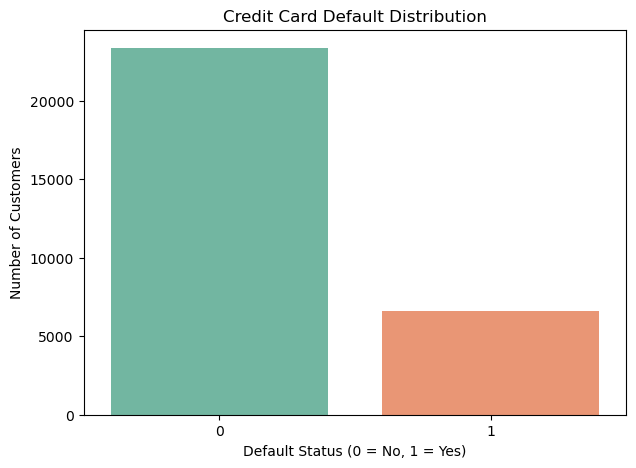

In [21]:

# Check target distribution
print(df["default_next_month"].value_counts())
print(df["default_next_month"].value_counts(normalize=True) * 100)

# Plot target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="default_next_month",
    hue="default_next_month",
    palette="Set2",
    legend=False
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()


**Observation:**

- 23,364 customers (77.88%) did not default.
- 6,636 customers (22.12%) defaulted.
- The dataset shows moderate class imbalance, with significantly fewer default cases.

This imbalance should be considered during model training. Accuracy alone may not be sufficient, so Precision, Recall, F1-score, and ROC-AUC should also be evaluated.

### 2.2 Credit Limit Distribution

We analyze the distribution of credit limits (`LIMIT_BAL`) and compare credit limits between customers who defaulted and those who did not.

This helps determine whether credit limit is associated with default risk.

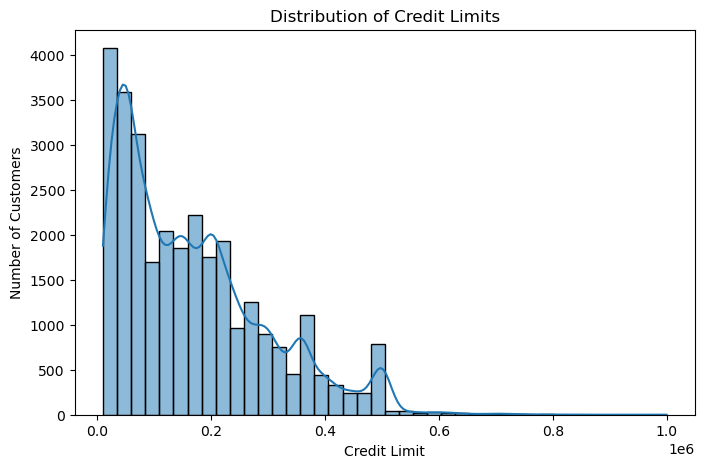

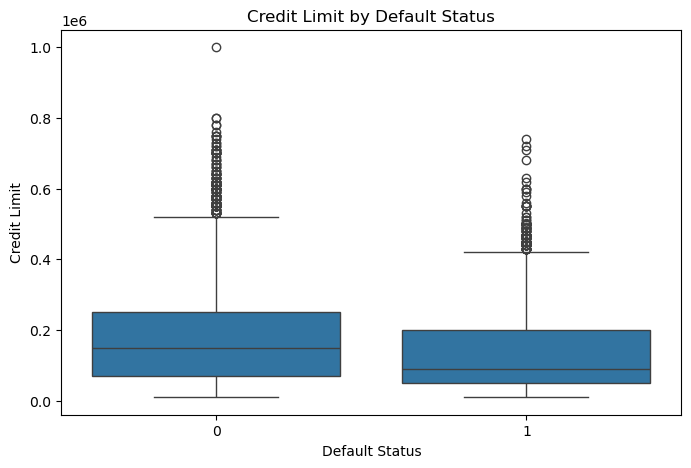

default_next_month
0    150000.0
1     90000.0
Name: LIMIT_BAL, dtype: float64

In [22]:

# Plot credit limit distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True
)

plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")
plt.show()

# Compare credit limit by default status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="default_next_month",
    y="LIMIT_BAL"
)

plt.title("Credit Limit by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Credit Limit")
plt.show()

# Check median credit limits
df.groupby("default_next_month")["LIMIT_BAL"].median()


**Observation:**

- The distribution of credit limits is right-skewed.
- Customers who did not default have a median credit limit of 150,000.
- Customers who defaulted have a lower median credit limit of 90,000.
- This suggests that lower credit limits are associated with a higher likelihood of default.

Credit limit may be a useful predictive feature for machine learning.

### 2.3 Age Distribution and Default Rate

We examine the age distribution and compare default rates across different age groups.

This helps us understand whether customer age is related to default behavior.

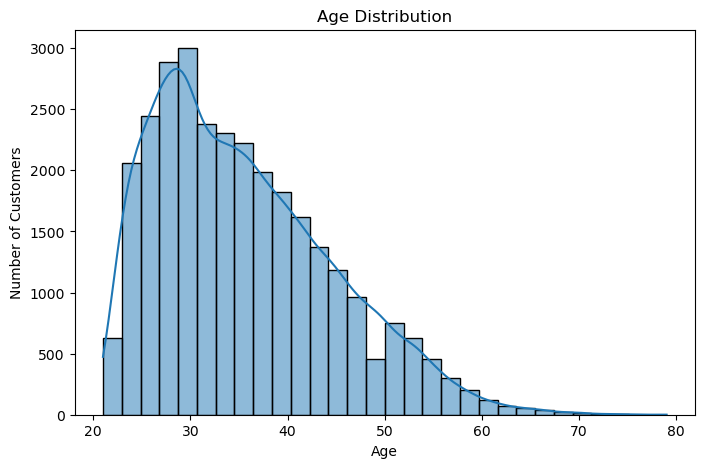

age_group
21-30    22.44
31-40    20.43
41-50    23.30
51-60    25.24
61+      26.84
Name: default_next_month, dtype: float64


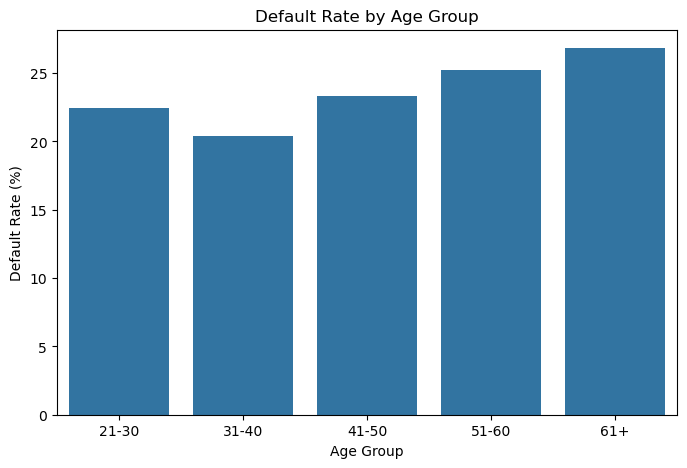

In [23]:

# Plot age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=30,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

# Create age groups for EDA
df["age_group"] = pd.cut(
    df["AGE"],
    bins=[20, 30, 40, 50, 60, 100],
    labels=["21-30", "31-40", "41-50", "51-60", "61+"]
)

# Calculate default rate by age group
age_default = (
    df.groupby("age_group", observed=True)["default_next_month"]
    .mean() * 100
)

print(age_default.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(x=age_default.index, y=age_default.values)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.show()


**Observation:**

- Most customers are between 21 and 40 years old.
- Default rates vary across different age groups.
- Customers aged 31–40 have a lower default rate than several other age groups.
- Older age groups contain fewer customers, so their default rates should be interpreted carefully.

Age may provide useful information, although it is unlikely to be sufficient for predicting default on its own.

### 2.4 Demographic Features and Default Rate

We analyze the relationship between demographic characteristics and credit card default.

The selected features are:

- `SEX`: Customer gender
- `EDUCATION`: Education level
- `MARRIAGE`: Marital status

We calculate the default rate for each category to identify differences in customer default behavior.

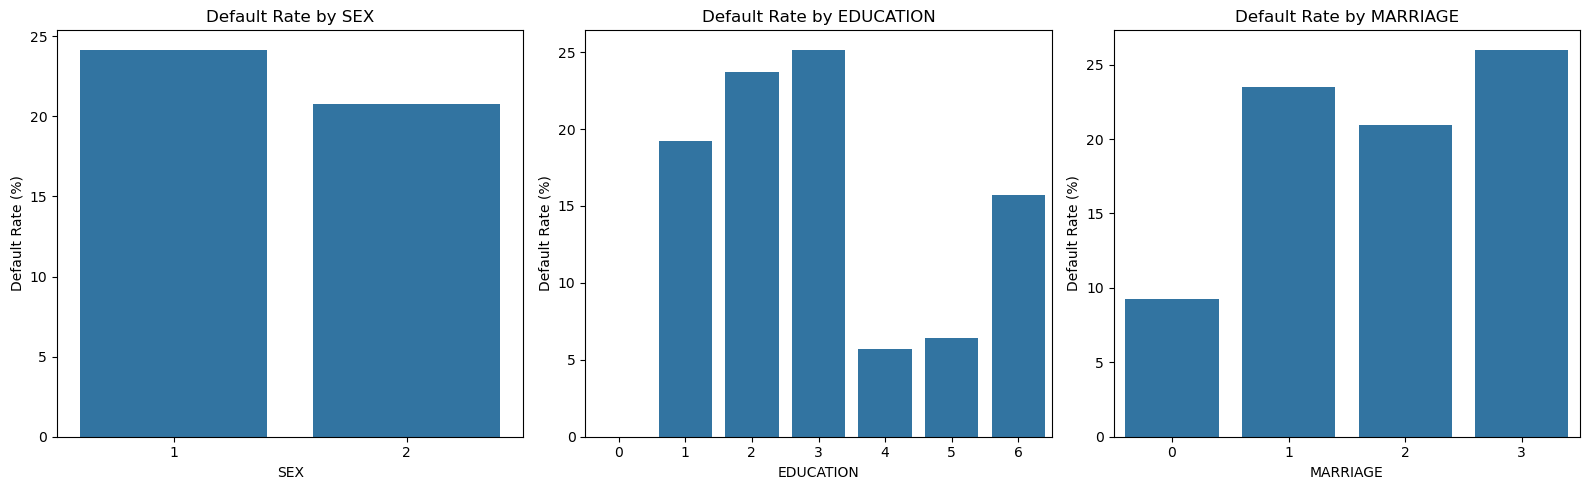

In [24]:

# Select demographic features
demographic_cols = ["SEX", "EDUCATION", "MARRIAGE"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, demographic_cols):

    # Calculate default rate
    rates = df.groupby(col)["default_next_month"].mean() * 100

    sns.barplot(
        x=rates.index,
        y=rates.values,
        ax=ax
    )

    ax.set_title(f"Default Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


**Observation:**

- Male customers have a higher default rate (24.17%) than female customers (20.78%).
- Customers with university or high-school education have higher default rates than those with graduate-school education.
- Married customers have a slightly higher default rate (23.47%) than single customers (20.93%).
- Some categories contain very few observations, which may affect the reliability of their default rates.

Demographic features show some differences in default behavior. However, these relationships do not imply causation, and sensitive features require careful consideration during modeling.

### 2.5 Repayment History Analysis

Repayment history is an important indicator of credit risk.

The variables `PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5`, and `PAY_6` represent repayment status over the previous six months.

We examine repayment patterns and their relationship with credit card default.

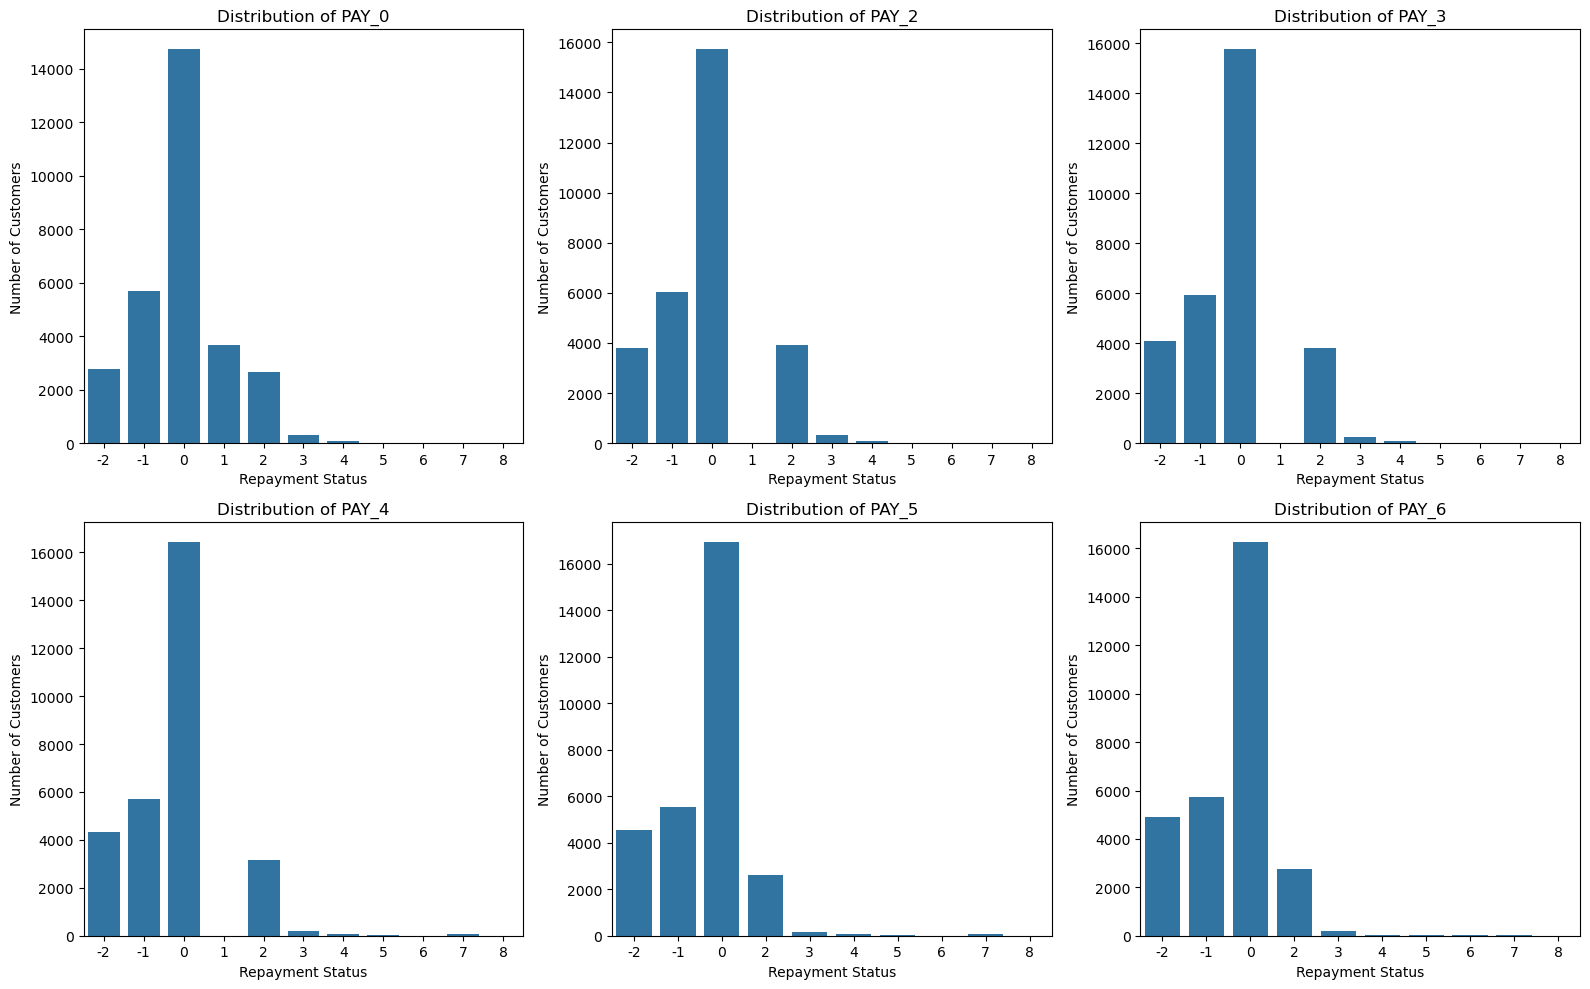

In [25]:

# Select repayment status features
pay_cols = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

# Plot repayment status distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, col in zip(axes.flat, pay_cols):

    sns.countplot(
        data=df,
        x=col,
        order=sorted(df[col].unique()),
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Repayment Status")
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


       count  default_rate
PAY_0                     
-2      2759         13.23
-1      5686         16.78
 0     14737         12.81
 1      3688         33.95
 2      2667         69.14
 3       322         75.78
 4        76         68.42
 5        26         50.00
 6        11         54.55
 7         9         77.78
 8        19         57.89


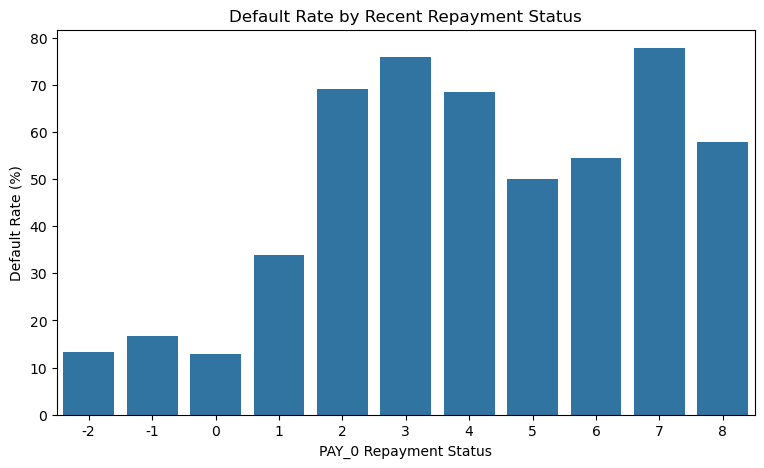

In [26]:

# Calculate default rate by recent repayment status
pay_default = (
    df.groupby("PAY_0")["default_next_month"]
    .agg(["mean", "count"])
)

pay_default["default_rate"] = pay_default["mean"] * 100

print(pay_default[["count", "default_rate"]].round(2))

# Plot default rates
plt.figure(figsize=(9, 5))

sns.barplot(
    x=pay_default.index,
    y=pay_default["default_rate"]
)

plt.title("Default Rate by Recent Repayment Status")
plt.xlabel("PAY_0 Repayment Status")
plt.ylabel("Default Rate (%)")
plt.show()


**Observation:**

- Most customers have repayment status values of -1 or 0, indicating relatively regular repayment behavior or the dataset's special repayment codes.
- Customers with recent repayment delays show considerably higher default rates.
- For `PAY_0 = 0`, the default rate is approximately 12.81%.
- For `PAY_0 = 2`, the default rate increases to approximately 69.14%.
- Some severe delay categories contain very few records, making their rates less stable.

Recent repayment status appears to be one of the most informative features for predicting credit card default.

### 2.6 Bill Amount Analysis

The variables `BILL_AMT1` to `BILL_AMT6` represent monthly credit card bill amounts.

We compare bill amounts across the previous six months and examine differences between default and non-default customers.

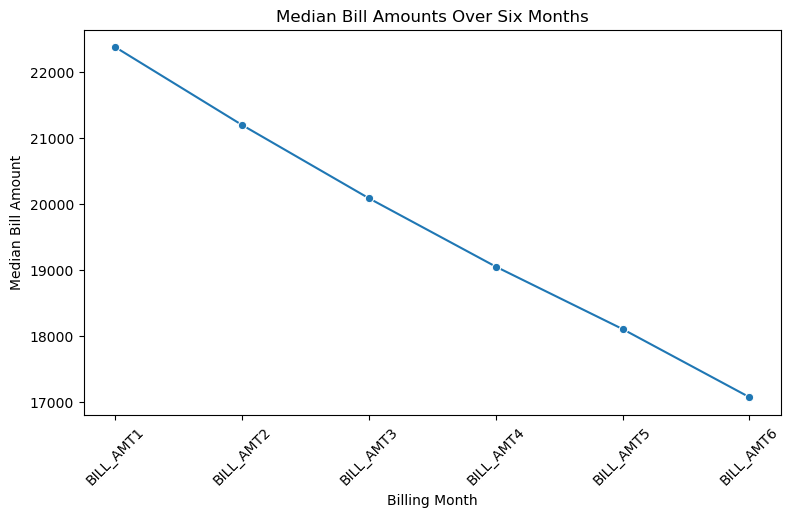

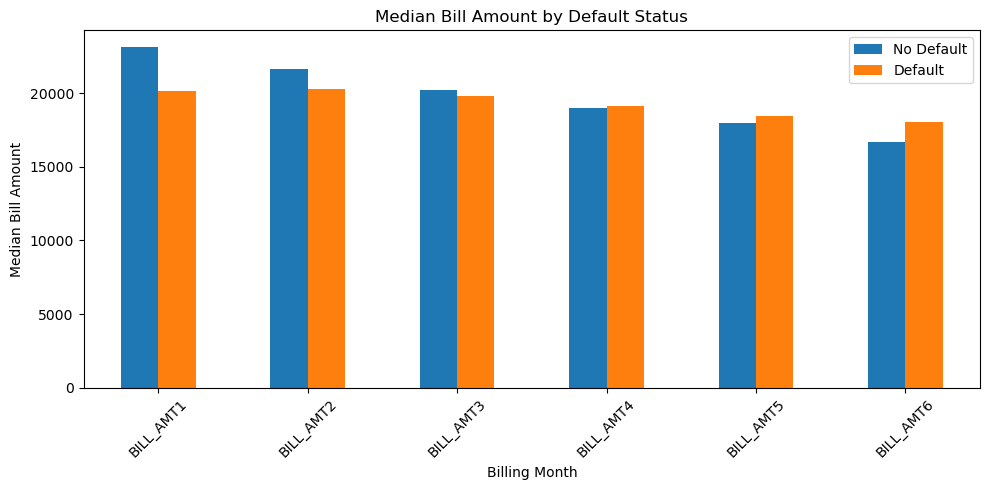

In [27]:

# Select bill amount features
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]

# Calculate median monthly bill amounts
bill_median = df[bill_cols].median()

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=bill_cols,
    y=bill_median.values,
    marker="o"
)

plt.title("Median Bill Amounts Over Six Months")
plt.xlabel("Billing Month")
plt.ylabel("Median Bill Amount")
plt.xticks(rotation=45)
plt.show()

# Compare bill amounts by default status
bill_by_default = (
    df.groupby("default_next_month")[bill_cols]
    .median()
    .T
)

bill_by_default.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Median Bill Amount by Default Status")
plt.xlabel("Billing Month")
plt.ylabel("Median Bill Amount")
plt.legend(["No Default", "Default"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observation:**

- Bill amounts vary across the six monthly periods.
- The median most recent bill amount (`BILL_AMT1`) is 23,119.5 for non-default customers and 20,185 for default customers.
- Default customers do not necessarily have higher absolute bill amounts.
- Bill amounts should be considered together with credit limits and repayment behavior.

Bill amounts alone may not strongly distinguish customers who default from those who do not.

### 2.7 Previous Payment Amount Analysis

The variables `PAY_AMT1` to `PAY_AMT6` represent previous monthly payment amounts.

We examine whether customers who default tend to make lower payments than customers who do not default.

default_next_month       0       1
PAY_AMT1            2459.5  1636.0
PAY_AMT2            2247.5  1533.5
PAY_AMT3            2000.0  1222.0
PAY_AMT4            1734.0  1000.0
PAY_AMT5            1765.0  1000.0
PAY_AMT6            1706.0  1000.0


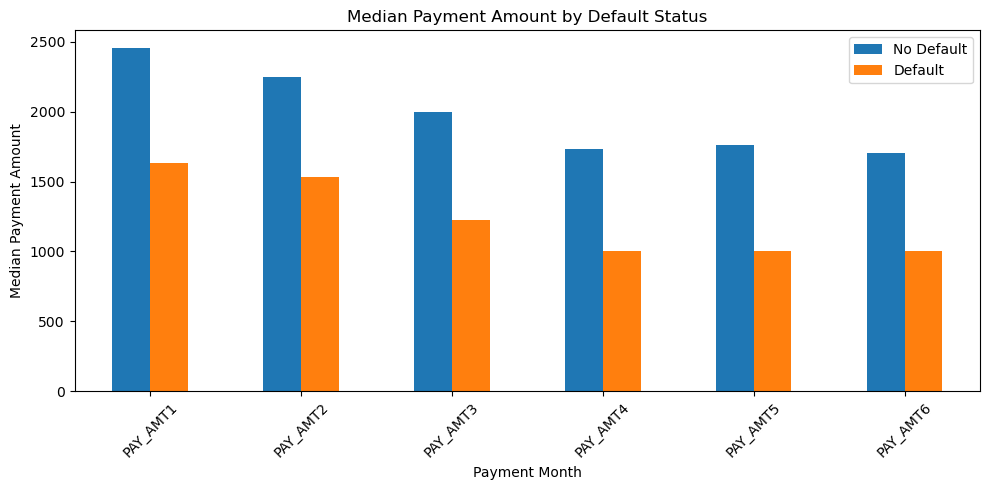

In [28]:

# Select payment amount features
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# Calculate median payment amounts by default status
payment_by_default = (
    df.groupby("default_next_month")[payment_cols]
    .median()
    .T
)

print(payment_by_default)

# Plot median payments
payment_by_default.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Median Payment Amount by Default Status")
plt.xlabel("Payment Month")
plt.ylabel("Median Payment Amount")
plt.legend(["No Default", "Default"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observation:**

- Customers who defaulted generally made lower monthly payments.
- The median most recent payment (`PAY_AMT1`) is 2,459.5 for non-default customers and 1,636 for default customers.
- Lower previous payment amounts may indicate increased financial difficulty.

Payment history may provide useful predictive information when combined with repayment status and credit limits.

### 2.8 Correlation Analysis

We examine correlations between numerical variables and the target variable.

A correlation heatmap helps identify relationships among features and potential multicollinearity.

We also calculate correlations with `default_next_month` to identify potentially useful predictors.

Correlation does not imply causation.

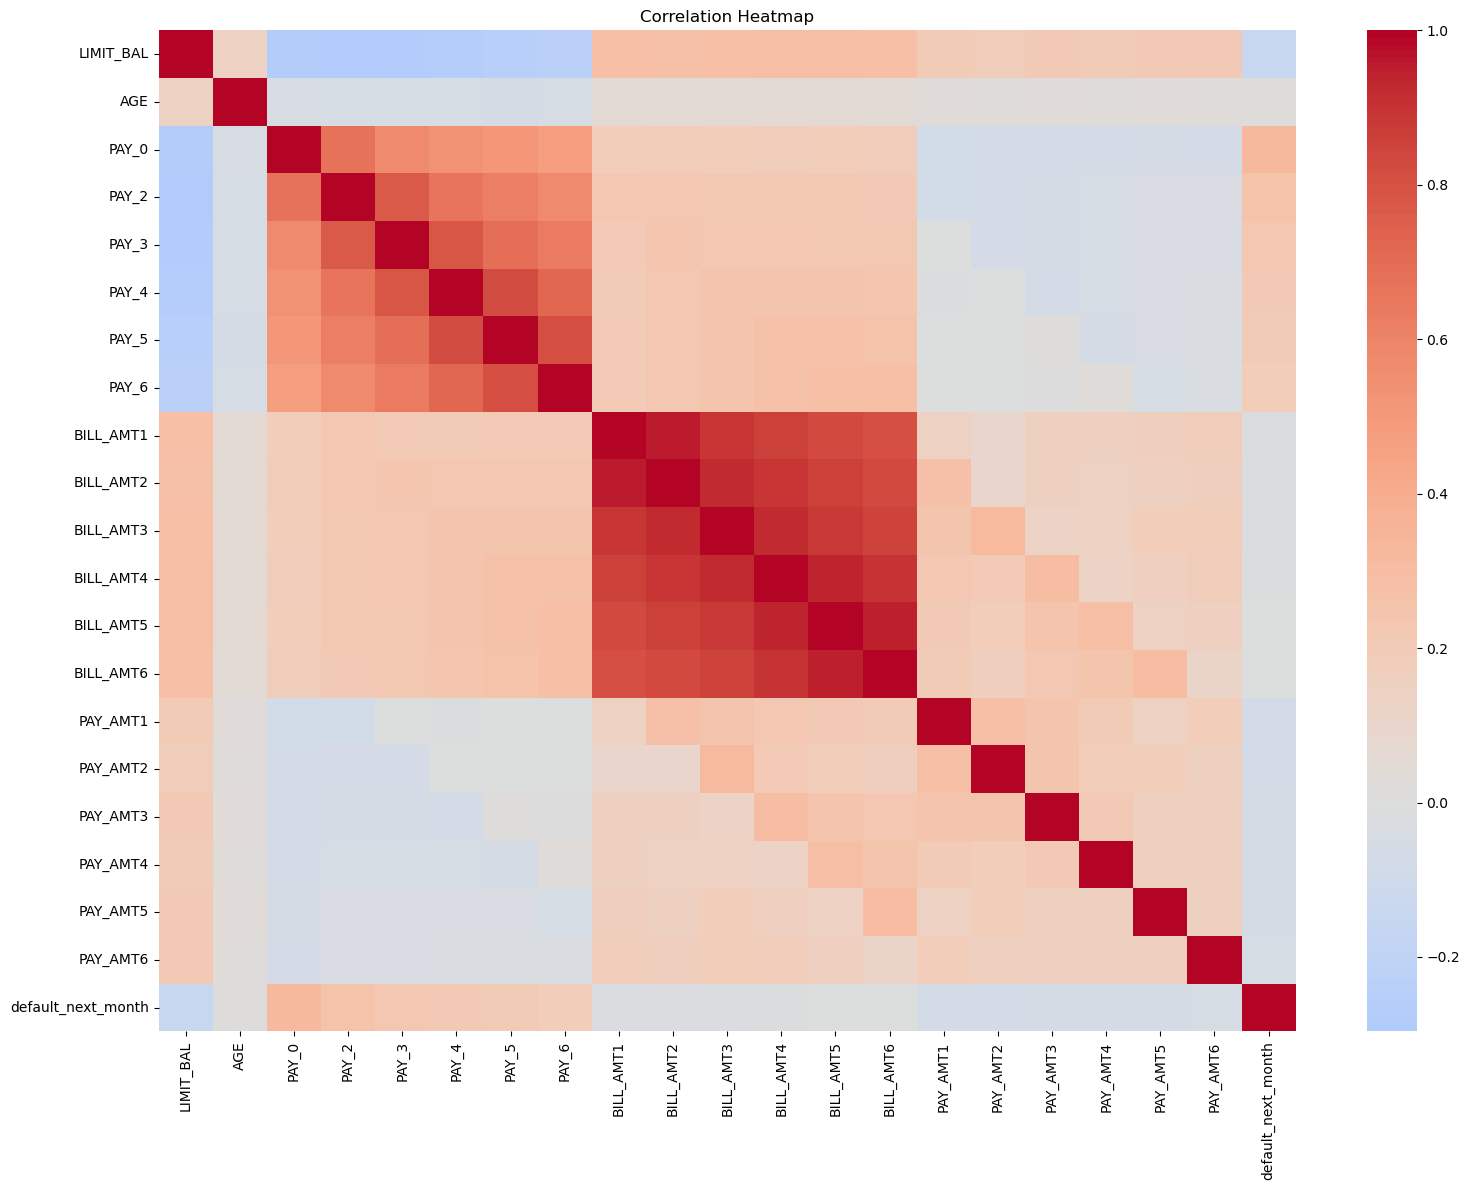

In [29]:

# Select numerical features
corr_cols = (
    ["LIMIT_BAL", "AGE"]
    + pay_cols
    + bill_cols
    + payment_cols
    + ["default_next_month"]
)

# Calculate correlations
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
PAY_AMT3    -0.056
PAY_AMT5    -0.055
PAY_AMT6    -0.053
BILL_AMT1   -0.020
BILL_AMT2   -0.014
BILL_AMT3   -0.014
BILL_AMT4   -0.010
BILL_AMT5   -0.007
BILL_AMT6   -0.005
AGE          0.014
PAY_6        0.187
PAY_5        0.204
PAY_4        0.217
PAY_3        0.235
PAY_2        0.264
PAY_0        0.325
Name: default_next_month, dtype: float64


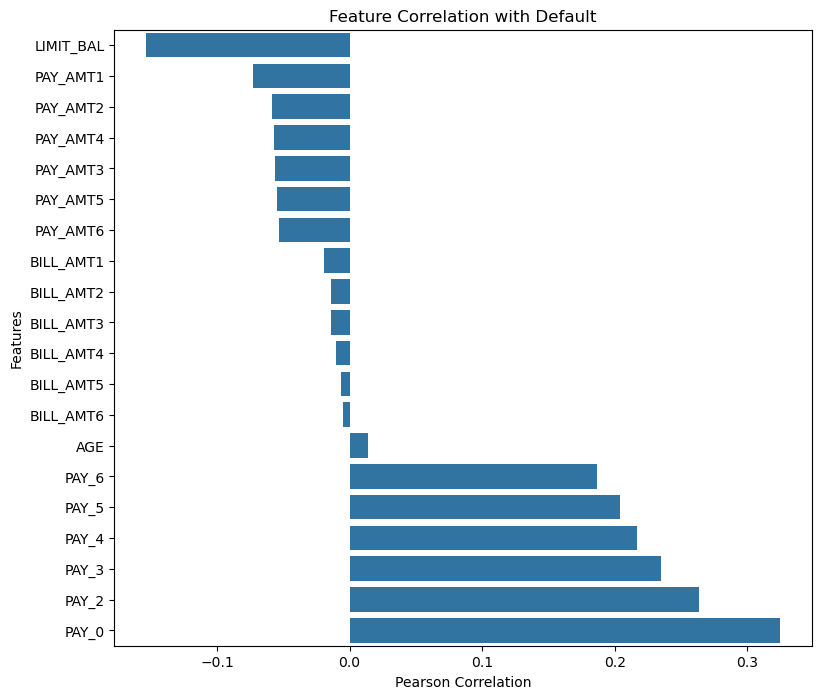

In [30]:

# Calculate correlation with target
target_corr = (
    corr_matrix["default_next_month"]
    .drop("default_next_month")
    .sort_values()
)

print(target_corr.round(3))

# Plot correlations
plt.figure(figsize=(9, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Feature Correlation with Default")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.show()


**Observation:**

- `PAY_0` has a relatively strong positive correlation with default (approximately 0.325).
- `LIMIT_BAL` has a negative correlation with default (approximately -0.154).
- `PAY_AMT1` also has a negative correlation (approximately -0.073).
- Monthly bill amounts are strongly correlated with each other.
- Repayment status features appear more directly related to default than most demographic and bill amount features.

Correlation analysis suggests that repayment behavior is particularly important. However, weak linear correlation does not necessarily mean a feature is unhelpful for machine learning.

### 2.9 EDA Summary and Key Findings

The exploratory data analysis provides several important findings:

1. **Class Imbalance:** The target variable is moderately imbalanced, with 22.12% default cases and 77.88% non-default cases.
2. **Credit Limit:** Customers with lower credit limits tend to have higher default risk.
3. **Demographic Features:** Age, gender, education, and marital status show some differences in default behavior.
4. **Repayment History:** Recent repayment delays show a strong association with default.
5. **Bill Amounts:** Absolute bill amounts alone do not clearly distinguish default and non-default customers.
6. **Payment Amounts:** Customers who default generally have lower previous payment amounts.
7. **Correlation:** Recent repayment status is one of the strongest individual indicators identified in the correlation analysis.

### Conclusion

The EDA suggests that repayment history, credit limits, and previous payment amounts may provide important information for predicting credit card default.

These findings will guide feature engineering, preprocessing, and machine learning model development.

### Next Step — Data Preprocessing for Machine Learning

The next stage will include:

- Defining features (`X`) and target (`y`)
- Removing the `ID` column
- Encoding categorical variables
- Train-test splitting
- Feature scaling where appropriate
- Handling class imbalance
- Preparing data for classification models

All preprocessing steps that learn from the data, including scaling and resampling, should be fitted only on the training data to prevent data leakage.

## Step 3 — Data Preprocessing & Feature Engineering



### 3.1 Define Features and Target

In this step, we separate the dataset into independent variables (X) and the target variable (y).

- **X:** Customer information, credit limits, repayment history, bill amounts, and previous payments.
- **y:** Credit card default status (`default_next_month`).

The `ID` column is removed because it is only a customer identifier and does not provide meaningful predictive information.

In [31]:

# Define target variable
target = "default_next_month"

# Remove columns not used for prediction
X = df.drop(
    columns=["ID", target, "age_group"],
    errors="ignore"
)

# Define target
y = df[target].astype(int)

# Check dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target distribution:")
print(y.value_counts(normalize=True) * 100)


X shape: (30000, 23)
y shape: (30000,)
Target distribution:
default_next_month
0    77.88
1    22.12
Name: proportion, dtype: float64


**Observation:**

- The dataset contains 30,000 customer records.
- The feature matrix contains 23 original predictive features.
- The target variable contains two classes: 0 (No Default) and 1 (Default).
- The `ID` column and the temporary `age_group` column have been excluded.

The dataset is ready for train-test splitting.

### 3.2 Train-Test Split

We split the dataset into training and testing sets.

- 80% Training Data
- 20% Testing Data

We use stratified splitting to maintain approximately the same class distribution in both datasets.

The test set will be reserved for final model evaluation.

In [32]:

from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Check dataset sizes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Check class distribution
print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("Testing distribution:")
print(y_test.value_counts(normalize=True) * 100)


X_train: (24000, 23)
X_test: (6000, 23)
Training distribution:
default_next_month
0    77.879167
1    22.120833
Name: proportion, dtype: float64
Testing distribution:
default_next_month
0    77.883333
1    22.116667
Name: proportion, dtype: float64


**Observation:**

- The training set contains 24,000 records.
- The test set contains 6,000 records.
- Stratified splitting preserves the original class proportions in both datasets.
- The testing dataset remains separate from the training data to support unbiased model evaluation.

### 3.3 Identify Numerical and Categorical Features

The dataset contains numerical and categorical variables.

Although several categorical variables are stored as integers, they should not be treated as continuous numerical features.

We separate these variables to apply appropriate preprocessing methods.

In [33]:

# Define categorical features
categorical_cols = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

# Define numerical features
numerical_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)
print("Number of categorical features:", len(categorical_cols))
print("Number of numerical features:", len(numerical_cols))


Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']
Numerical features: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Number of categorical features: 3
Number of numerical features: 20


**Observation:**

- Three features are treated as categorical variables: `SEX`, `EDUCATION`, and `MARRIAGE`.
- The remaining 20 features are retained as numerical or ordered repayment variables.
- Categorical variables will be encoded, while numerical variables can be scaled when required.

Repayment status variables are currently kept as ordered numerical features because their values describe repayment delay levels. Their unusual negative codes should be considered when interpreting results.

### 3.4 Feature Engineering

Feature engineering creates new variables from existing data to improve the representation of customer repayment behavior.

We create the following features:

- `avg_bill_amount`: Average bill amount over six months.
- `avg_payment_amount`: Average payment amount over six months.
- `payment_to_bill_ratio`: Ratio of total payments to total positive bill amounts.
- `credit_utilization`: Most recent bill amount relative to the credit limit.
- `max_payment_delay`: Maximum recorded repayment status.
- `months_with_delay`: Number of months with a positive repayment delay status.

These features may help the model identify repayment patterns and financial risk.

In [34]:

# Create new features
def create_features(data):
    data = data.copy()

    bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
    payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
    status_cols = [
        "PAY_0", "PAY_2", "PAY_3",
        "PAY_4", "PAY_5", "PAY_6"
    ]

    # Average bill and payment amounts
    data["avg_bill_amount"] = data[bill_cols].mean(axis=1)
    data["avg_payment_amount"] = data[payment_cols].mean(axis=1)

    # Payment ratio with safe denominator
    total_bills = data[bill_cols].clip(lower=0).sum(axis=1)
    total_payments = data[payment_cols].sum(axis=1)

    data["payment_to_bill_ratio"] = (
        total_payments / total_bills.replace(0, np.nan)
    )

    # Credit utilization
    data["credit_utilization"] = (
        data["BILL_AMT1"] / data["LIMIT_BAL"]
    )

    # Repayment delay features
    data["max_payment_delay"] = data[status_cols].max(axis=1)
    data["months_with_delay"] = (
        data[status_cols] > 0
    ).sum(axis=1)

    return data


# Apply feature engineering
X_train_fe = create_features(X_train)
X_test_fe = create_features(X_test)

print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

X_train_fe.head()


Training shape: (24000, 29)
Testing shape: (6000, 29)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,avg_bill_amount,avg_payment_amount,payment_to_bill_ratio,credit_utilization,max_payment_delay,months_with_delay
10029,340000,2,1,2,30,-1,-1,-1,-1,0,...,47258,983,20691,23849,23969.000000,20738.166667,0.865208,0.025209,0,0
17540,100000,2,2,1,36,1,2,2,2,2,...,2000,0,2000,3500,33671.333333,1750.000000,0.051973,0.321960,2,5
20357,130000,1,3,1,27,-1,-1,-1,-1,-2,...,0,0,2699,3766,1092.166667,1636.500000,1.498398,0.003846,-1,0
20217,150000,2,1,1,51,1,-2,-2,-2,-2,...,0,0,0,0,0.000000,0.000000,NaN,0.000000,1,1
17264,240000,2,2,1,46,0,0,0,0,-2,...,0,0,0,0,85530.333333,2262.166667,0.026449,0.738421,0,0


In [35]:

# Check new features
new_features = [
    "avg_bill_amount",
    "avg_payment_amount",
    "payment_to_bill_ratio",
    "credit_utilization",
    "max_payment_delay",
    "months_with_delay"
]

print(X_train_fe[new_features].describe().round(2))

# Check missing and infinite values
print(X_train_fe[new_features].isna().sum())

print(
    np.isinf(X_train_fe[new_features]).sum()
)


       avg_bill_amount  avg_payment_amount  payment_to_bill_ratio  \
count         24000.00            24000.00               23240.00   
mean          44940.38             5325.65                   0.51   
std           63124.79            10495.48                   6.20   
min          -56043.17                0.00                   0.00   
25%            4882.38             1114.96                   0.04   
50%           21130.17             2400.17                   0.09   
75%           57011.79             5642.42                   0.62   
max          877313.83           627344.33                 797.00   

       credit_utilization  max_payment_delay  months_with_delay  
count            24000.00           24000.00           24000.00  
mean                 0.42               0.44               0.84  
std                  0.41               1.34               1.56  
min                 -0.62              -2.00               0.00  
25%                  0.02               0.00    

**Observation:**

- Six new features have been created to summarize customers' financial and repayment behavior.
- The number of predictive features increases from 23 to 29.
- The new variables provide additional information about average bills, payment behavior, credit utilization, and repayment delays.
- Missing values may appear in `payment_to_bill_ratio` when the total positive bill amount is zero.

These missing values will be handled during preprocessing. The payment ratio is an approximate behavioral indicator rather than an exact debt repayment rate.

### 3.5 Update Numerical Features

After feature engineering, we update the numerical feature list to include the newly created variables.

This ensures that all numerical features are included in the preprocessing pipeline.

In [36]:

# Update numerical features
numerical_cols = [
    col for col in X_train_fe.columns
    if col not in categorical_cols
]

# Replace infinite values with missing values
X_train_fe = X_train_fe.replace([np.inf, -np.inf], np.nan)
X_test_fe = X_test_fe.replace([np.inf, -np.inf], np.nan)

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))
print("Total features:", X_train_fe.shape[1])


Numerical features: 26
Categorical features: 3
Total features: 29


**Observation:**

- The dataset now contains 26 numerical features and 3 categorical features.
- Infinite values have been replaced with missing values where necessary.
- The dataset is ready for categorical encoding and numerical scaling.

### 3.6 Categorical Encoding and Feature Scaling

Machine learning algorithms require numerical input.

We apply:

- **One-Hot Encoding:** Converts categorical variables into binary indicator columns.
- **StandardScaler:** Standardizes numerical features using the training set mean and standard deviation.
- **SimpleImputer:** Handles missing values using the median for numerical features and the most frequent value for categorical features.

These transformations are fitted only on the training data to prevent data leakage.

In [37]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


**Observation:**

- Numerical features will be standardized to a common scale.
- Categorical features will be converted into binary indicator variables.
- Missing values will be imputed using statistics learned from the training data.
- The preprocessing pipeline helps prevent data leakage and ensures consistent transformations for the test set.

Standardization is particularly useful for Logistic Regression. Tree-based algorithms such as Random Forest generally do not require feature scaling.

### 3.7 Apply Preprocessing

We apply the preprocessing pipeline to the training and testing datasets.

The pipeline is fitted on the training set only. The same transformations are then applied to the test set.

This ensures that the test set does not influence preprocessing parameters.

In [38]:

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train_fe)

# Transform test data
X_test_processed = preprocessor.transform(X_test_fe)

# Check processed data shapes
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

# Check number of output features
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))


Training shape: (24000, 39)
Testing shape: (6000, 39)
Number of processed features: 39


In [39]:

# Convert to dense arrays for validation
train_array = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)

test_array = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else np.asarray(X_test_processed)
)

# Check missing and infinite values
print("Train missing:", np.isnan(train_array).sum())
print("Test missing:", np.isnan(test_array).sum())

print("Train infinite:", np.isinf(train_array).sum())
print("Test infinite:", np.isinf(test_array).sum())


Train missing: 0
Test missing: 0
Train infinite: 0
Test infinite: 0


**Observation:**

- Both training and testing datasets have been transformed using the same preprocessing rules.
- One-Hot Encoding increases the total number of features.
- Numerical features are standardized using the training data statistics.
- The transformed datasets are ready for initial classification experiments.

Before model training, the validation results should confirm that no missing or infinite values remain.


### 3.8 Check Class Imbalance

The dataset contains fewer default customers than non-default customers.

We examine the class distribution in the training set before applying any imbalance handling techniques.

Class imbalance can affect model predictions, especially the identification of default customers.

Possible approaches include class weighting and SMOTE.

Class counts:
default_next_month
0    18691
1     5309
Name: count, dtype: int64

Class percentages:
default_next_month
0    77.88
1    22.12
Name: proportion, dtype: float64


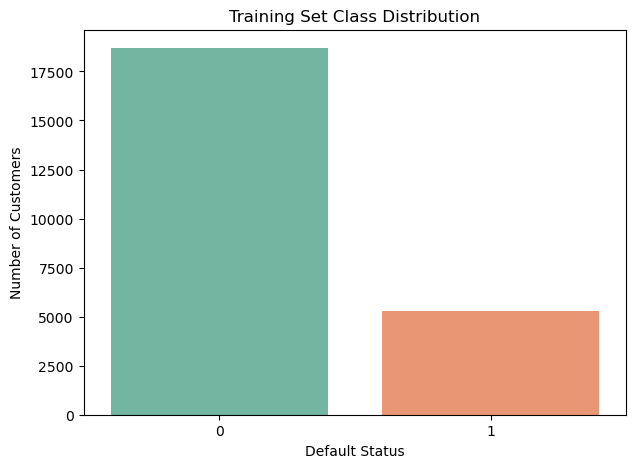

Imbalance ratio: 3.52


In [40]:

# Check training class distribution
class_counts = y_train.value_counts().sort_index()

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

# Plot training class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y_train,
    hue=y_train,
    palette="Set2",
    legend=False
)

plt.title("Training Set Class Distribution")
plt.xlabel("Default Status")
plt.ylabel("Number of Customers")
plt.show()

# Calculate imbalance ratio
imbalance_ratio = class_counts.loc[0] / class_counts.loc[1]

print("Imbalance ratio:", round(imbalance_ratio, 2))


**Observation:**

- Approximately 77.88% of training samples belong to Class 0 (No Default).
- Approximately 22.12% belong to Class 1 (Default).
- The majority-to-minority class ratio is approximately 3.52:1.
- The dataset shows moderate class imbalance.

During model training, we will compare baseline models with imbalance handling techniques such as `class_weight="balanced"` and SMOTE.

SMOTE will only be applied within the training process, not to the test set.

### 3.9 Final Preprocessing Summary

The data preprocessing and feature engineering stage has prepared the dataset for machine learning classification.

**Completed steps:**

1. Defined independent variables and the binary target.
2. Removed customer ID and temporary EDA features.
3. Split the dataset into training (80%) and testing (20%) sets.
4. Identified numerical and categorical variables.
5. Created six additional features related to financial and repayment behavior.
6. Prepared One-Hot Encoding and StandardScaler transformations.
7. Applied preprocessing using training data statistics only.
8. Examined class imbalance in the training dataset.

**Key Findings:**

- The original dataset contains 30,000 customer records.
- The training set contains 24,000 records and the test set contains 6,000 records.
- Feature engineering increased the number of input features from 23 to 29 before encoding.
- The target remains moderately imbalanced, with approximately 22.12% default cases.

### Conclusion

The dataset is now prepared for initial machine learning experiments.

The next stage will compare different classification algorithms and evaluate their ability to predict credit card default.



In [41]:

# Final checks
print("Original features:", X.shape[1])
print("Engineered features:", X_train_fe.shape[1])
print("Encoded features:", len(feature_names))

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

print("Train classes:", sorted(y_train.unique()))
print("Test classes:", sorted(y_test.unique()))


Original features: 23
Engineered features: 29
Encoded features: 39
Training samples: 24000
Testing samples: 6000
Train classes: [np.int64(0), np.int64(1)]
Test classes: [np.int64(0), np.int64(1)]


## Step 4 — Machine Learning Model Development

### 4.1 SGD Classifier

Stochastic Gradient Descent (SGD) is an optimization method used to train machine learning models efficiently.

In this project, we use `SGDClassifier` with logistic loss for binary classification.

The objective is to predict whether a customer will default on their credit card payment next month.

**Target variable:**

- 0: No Default
- 1: Default

We first train a baseline SGD model without class imbalance handling and evaluate its performance on the test set.

### 4.2 Import Libraries for Model Training

We import the machine learning algorithms and evaluation metrics required to train and evaluate the SGD classifier.

In [42]:

from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from sklearn.pipeline import Pipeline


### 4.3 Train Baseline SGD Classifier

We train an SGD classifier using logistic loss.

The model is trained without class weighting or resampling to establish a baseline.

We use a preprocessing pipeline to ensure consistent feature transformations.

In [43]:

# Create baseline SGD pipeline
sgd_baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=2000,
        tol=1e-3,
        random_state=SEED
    ))
])

# Train the model
sgd_baseline.fit(X_train_fe, y_train)

# Make predictions
y_pred_sgd = sgd_baseline.predict(X_test_fe)

print("SGD model trained successfully.")


SGD model trained successfully.


### 4.4 Baseline Model Evaluation

We evaluate the SGD classifier using the following metrics:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Proportion of predicted defaults that are actual defaults.
- **Recall:** Proportion of actual defaults correctly identified.
- **F1-score:** Harmonic mean of Precision and Recall.
- **ROC-AUC:** Ability of the model to distinguish between default and non-default customers.

These metrics provide a more complete evaluation for imbalanced classification.

In [44]:

# Predict default probabilities
y_prob_sgd = sgd_baseline.predict_proba(X_test_fe)[:, 1]

# Calculate evaluation metrics
sgd_accuracy = accuracy_score(y_test, y_pred_sgd)
sgd_precision = precision_score(y_test, y_pred_sgd, zero_division=0)
sgd_recall = recall_score(y_test, y_pred_sgd, zero_division=0)
sgd_f1 = f1_score(y_test, y_pred_sgd, zero_division=0)
sgd_auc = roc_auc_score(y_test, y_prob_sgd)

# Display evaluation results
sgd_results = pd.DataFrame({
    "Model": ["SGD Baseline"],
    "Accuracy": [sgd_accuracy],
    "Precision": [sgd_precision],
    "Recall": [sgd_recall],
    "F1-score": [sgd_f1],
    "ROC-AUC": [sgd_auc]
})

sgd_results.round(4)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SGD Baseline,0.8107,0.6548,0.3044,0.4156,0.7525


### 4.5 Classification Report

The classification report provides Precision, Recall, F1-score, and support for each class.

This helps identify whether the SGD classifier performs better on non-default customers than on default customers.

In [45]:

# Calculate training accuracy
train_accuracy = sgd_baseline.score(X_train_fe, y_train)
print(f"Train Accuracy: {train_accuracy:.4f}")


# Display classification report
print(
    classification_report(
        y_test,
        y_pred_sgd,
        target_names=["No Default", "Default"],
        zero_division=0
    )
)


Train Accuracy: 0.8072
              precision    recall  f1-score   support

  No Default       0.83      0.95      0.89      4673
     Default       0.65      0.30      0.42      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.63      0.65      6000
weighted avg       0.79      0.81      0.78      6000



### 4.6 Confusion Matrix

The confusion matrix shows the number of correct and incorrect predictions.

It contains four components:

- True Negative (TN): Correctly predicted non-default customers.
- False Positive (FP): Non-default customers incorrectly predicted as default.
- False Negative (FN): Default customers incorrectly predicted as non-default.
- True Positive (TP): Correctly predicted default customers.

False negatives are especially important because they represent default cases missed by the model.

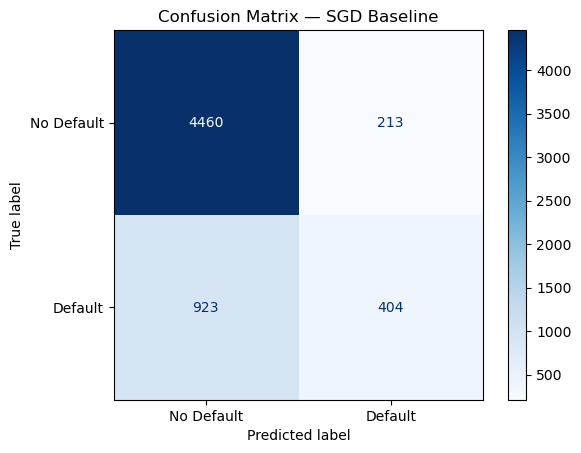

In [46]:

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_sgd,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — SGD Baseline")
plt.show()


**Observation:**

The confusion matrix shows how many default and non-default customers were correctly classified.

False negatives represent customers who defaulted but were predicted as non-default.

A high number of false negatives would indicate that the model has difficulty identifying customers at risk.

Reducing false negatives may improve the model's usefulness for credit risk prediction, although this may increase false positives.

### 4.7 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance.

We use Random Forest to predict credit card default and compare its results with SGD.

In [47]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1
    ))
])

# Train the model
rf_baseline.fit(X_train_fe, y_train)

# Predict test data
y_pred_rf = rf_baseline.predict(X_test_fe)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.


### 4.8 Baseline Random Forest Evaluation

We evaluate training and testing accuracy, Precision, Recall, and F1-score to measure classification performance and identify possible overfitting.

In [48]:

# Calculate training accuracy
rf_train_accuracy = rf_baseline.score(X_train_fe, y_train)
print(f"Train Accuracy: {rf_train_accuracy:.4f}")

# Calculate test metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

# Display results
rf_results = pd.DataFrame({
    "Model": ["Random Forest Baseline"],
    "Train Accuracy": [rf_train_accuracy],
    "Test Accuracy": [rf_accuracy],
    "Precision": [rf_precision],
    "Recall": [rf_recall],
    "F1-score": [rf_f1]
})

display(rf_results.round(4))


Train Accuracy: 0.9994


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score
0,Random Forest Baseline,0.9994,0.82,0.661,0.3821,0.4842


### 4.9 Classification Report and Confusion Matrix

We examine classification performance for both classes and identify incorrect predictions.

              precision    recall  f1-score   support

  No Default       0.84      0.94      0.89      4673
     Default       0.66      0.38      0.48      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.69      6000
weighted avg       0.80      0.82      0.80      6000



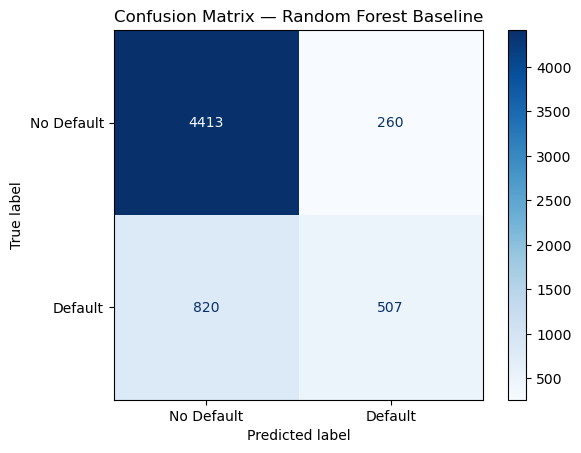

In [49]:

# Display classification report
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Default", "Default"],
    zero_division=0
))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — Random Forest Baseline")
plt.show()


**Observation:**

- The confusion matrix shows correct and incorrect classifications.
- False negatives represent default customers incorrectly predicted as non-default.
- A lower number of false negatives indicates better detection of default customers, although false positives should also be considered.

### 4.10 XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm that builds decision trees sequentially to improve prediction performance.

We use XGBoost to predict credit card default and compare its performance with previous classification models.

In [50]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# Create XGBoost pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=-1
    ))
])

# Train the model
xgb_model.fit(X_train_fe, y_train)

# Predict test data
y_pred_xgb = xgb_model.predict(X_test_fe)

print("XGBoost model trained successfully.")


XGBoost model trained successfully.


### 4.11 XGBoost Model Evaluation

We evaluate the model using Train Accuracy, Test Accuracy, Precision, Recall, and F1-score.

Comparing training and testing accuracy helps identify possible overfitting.

In [51]:

# Calculate training accuracy
xgb_train_accuracy = xgb_model.score(X_train_fe, y_train)

print(f"Train Accuracy: {xgb_train_accuracy:.4f}")

# Calculate test metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb, zero_division=0)
xgb_recall = recall_score(y_test, y_pred_xgb, zero_division=0)
xgb_f1 = f1_score(y_test, y_pred_xgb, zero_division=0)

# Display results
xgb_results = pd.DataFrame({
    "Model": ["XGBoost"],
    "Train Accuracy": [xgb_train_accuracy],
    "Test Accuracy": [xgb_accuracy],
    "Precision": [xgb_precision],
    "Recall": [xgb_recall],
    "F1-score": [xgb_f1]
})

display(xgb_results.round(4))


Train Accuracy: 0.8926


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score
0,XGBoost,0.8926,0.817,0.6485,0.3768,0.4766


### 4.12 Classification Report

The classification report shows Precision, Recall, and F1-score for both default and non-default customers.

In [52]:

# Display classification report
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Default", "Default"],
    zero_division=0
))


              precision    recall  f1-score   support

  No Default       0.84      0.94      0.89      4673
     Default       0.65      0.38      0.48      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000



### 4.13 XGBoost Confusion Matrix

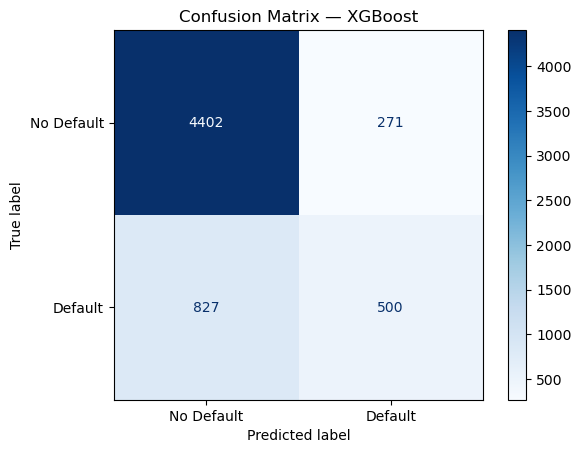

In [53]:

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — XGBoost")
plt.show()


### 4.14 SGD Results Update

In [54]:

# Calculate SGD training accuracy
sgd_train_accuracy = sgd_baseline.score(X_train_fe, y_train)

# Calculate SGD test accuracy
sgd_test_accuracy = accuracy_score(y_test, y_pred_sgd)

# Update SGD results
sgd_results["Train Accuracy"] = sgd_train_accuracy
sgd_results["Test Accuracy"] = sgd_test_accuracy

# Check updated results
display(sgd_results.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Train Accuracy,Test Accuracy
0,SGD Baseline,0.8107,0.6548,0.3044,0.4156,0.7525,0.8072,0.8107


### 4.15 Baseline Model Comparison

In [55]:

# Combine model results
model_comparison = pd.concat([
    sgd_results,
    rf_results,
    xgb_results
], ignore_index=True)

# Select evaluation metrics
model_comparison = model_comparison[
    [
        "Model",
        "Train Accuracy",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ]
]

# Display comparison
display(model_comparison.round(4))


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score
0,SGD Baseline,0.8072,0.8107,0.6548,0.3044,0.4156
1,Random Forest Baseline,0.9994,0.8200,0.6610,0.3821,0.4842
2,XGBoost,0.8926,0.8170,0.6485,0.3768,0.4766


### 4.16 Model Comparison — Observation

- Random Forest achieved the highest Test Accuracy (82.00%) and F1-score (0.4842).
- However, its very high Train Accuracy (99.94%) suggests substantial overfitting.
- XGBoost achieved comparable performance with a smaller train-test accuracy gap.
- SGD showed consistent training and testing accuracy but had the lowest Recall and F1-score.
- All three models have relatively low Recall for default customers, indicating room for improvement.

**Conclusion:** Random Forest achieved the highest F1-score among the initial baseline models, but its large train-test accuracy gap suggests substantial overfitting. XGBoost was selected for further hyperparameter optimization and class imbalance handling.

### 4.17 Hyperparameter Tuning — XGBoost Classifier

Hyperparameter tuning aims to improve model performance by finding the best combination of parameters.

We focus on XGBoost to improve prediction accuracy, reduce overfitting, and achieve a better balance between Precision and Recall.

Three optimization methods will be applied:

1. **Randomized Search:** Explore different parameter combinations.
2. **Grid Search:** Refine the best parameters from Randomized Search.
3. **Manual Search:** Adjust `scale_pos_weight` to address class imbalance.

Stratified Cross-Validation will be used to evaluate parameter combinations while preserving class proportions.

#### 4.17.1 XGBoost Hyperparameter Search Space

We define the main XGBoost hyperparameters to be optimized.

- `n_estimators`: Number of boosting trees.
- `max_depth`: Maximum depth of each tree.
- `learning_rate`: Contribution of each tree.
- `subsample`: Proportion of training samples used per tree.
- `colsample_bytree`: Proportion of features used per tree.
- `min_child_weight`: Controls minimum leaf weight.
- `gamma`: Minimum loss reduction required for a split.

These parameters control model complexity and help reduce overfitting.

In [56]:

from sklearn.model_selection import StratifiedKFold

# Define cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Define XGBoost search space
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [3, 4, 5, 6, 7],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__gamma": [0, 0.1, 0.3, 0.5]
}

print("Search space defined successfully.")


Search space defined successfully.


### 4.17.2 Optimization Metric

We use **F1-score** as the primary optimization metric because the dataset is imbalanced and both Precision and Recall are important for credit default prediction.

- **Recall** helps identify more actual default customers and reduce missed defaults.
- **Precision** helps limit false alarms and unnecessary customer reviews.
- **F1-score** balances these two objectives, avoiding models that perform well on one metric but poorly on the other.

Accuracy is also monitored, but it may be misleading when the majority of customers do not default.

**Business Rationale:** F1-score provides a reasonable balance between early default detection and false alarm control. However, the optimal business decision ultimately depends on actual financial and operational costs.

In [57]:

# Define primary scoring metric
scoring_metric = "f1"

print("Optimization metric:", scoring_metric)


Optimization metric: f1


### 4.18 Randomized Search — XGBoost Classifier

Randomized Search tests different hyperparameter combinations to identify a better-performing XGBoost model.

We use 3-fold Stratified Cross-Validation and F1-score to evaluate each combination.

The search is performed using the training dataset only.

In [58]:

from sklearn.model_selection import RandomizedSearchCV

# Define Randomized Search
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=20,
    scoring=scoring_metric,
    cv=cv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

# Train Randomized Search
random_search.fit(X_train_fe, y_train)

# Display best results
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV F1-score:")
print(round(random_search.best_score_, 4))


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 1, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 1.0}

Best CV F1-score:
0.4751


**Observation:**

- Randomized Search evaluated 20 parameter combinations using 3-fold Cross-Validation.
- The best CV F1-score was 0.4751.
- The selected parameters include `max_depth=3`, `n_estimators=300`, and `learning_rate=0.1`.
- The best parameters will be used for targeted refinement with Grid Search.

### 4.19 Randomized Search — Model Evaluation

We examine the best model selected by Randomized Search using its cross-validation results and training performance.

The test set remains reserved for final evaluation after hyperparameter tuning.

In [59]:

# Get the best model
xgb_random_best = random_search.best_estimator_

# Calculate training accuracy
random_train_accuracy = xgb_random_best.score(
    X_train_fe, y_train
)

# Predict training data
y_train_pred_random = xgb_random_best.predict(X_train_fe)

# Display results
print(f"Train Accuracy: {random_train_accuracy:.4f}")
print(f"Train F1-score: {f1_score(y_train, y_train_pred_random):.4f}")
print(f"Best CV F1-score: {random_search.best_score_:.4f}")


Train Accuracy: 0.8335
Train F1-score: 0.5149
Best CV F1-score: 0.4751


In [60]:

# Get best Random Search model
model = random_search.best_estimator_

# Predictions
y_pred_train = model.predict(X_train_fe)
y_pred_test = model.predict(X_test_fe)

# Accuracy
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"\nAccuracy (Train): {acc_train * 100:.2f}%")
print(f"Accuracy (Test): {acc_test * 100:.2f}%")

# Classification Report
print("\nClassification Report (Test):")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=["No Default", "Default"]
    )
)

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

# ROC-AUC
y_pred_proba = model.predict_proba(X_test_fe)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\nROC-AUC (Test): {roc_auc:.4f}")



Accuracy (Train): 83.35%
Accuracy (Test): 82.05%

Classification Report (Test):
              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      4673
     Default       0.67      0.37      0.48      1327

    accuracy                           0.82      6000
   macro avg       0.76      0.66      0.69      6000
weighted avg       0.80      0.82      0.80      6000

Confusion Matrix:
[[4428  245]
 [ 832  495]]

ROC-AUC (Test): 0.7820


### 4.20 Grid Search — Targeted Refinement of XGBoost Parameters

Grid Search refines the best hyperparameters identified by Randomized Search.

We test a smaller range of parameter values to improve F1-score and reduce overfitting.

Stratified 3-fold Cross-Validation is used, with F1-score as the primary evaluation metric.

In [61]:

from sklearn.model_selection import GridSearchCV

# Define refined parameter grid
param_grid = {
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__min_child_weight": [1, 3],
    "classifier__gamma": [0, 0.1, 0.2]
}

# Use best Random Search model
grid_search = GridSearchCV(
    estimator=random_search.best_estimator_,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Grid Search configured successfully.")


Grid Search configured successfully.


In [62]:

# Train Grid Search
grid_search.fit(X_train_fe, y_train)

# Display best parameters
print("Best Grid Search Parameters:")
print(grid_search.best_params_)

# Display best CV F1-score
print("\nBest Grid Search CV F1-score:")
print(round(grid_search.best_score_, 4))


Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Grid Search Parameters:
{'classifier__gamma': 0, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 4, 'classifier__min_child_weight': 3}

Best Grid Search CV F1-score:
0.4776


In [63]:

# Get best Grid Search model
xgb_grid_best = grid_search.best_estimator_

# Calculate training accuracy
grid_train_accuracy = xgb_grid_best.score(
    X_train_fe, y_train
)

# Calculate training F1-score
y_train_pred_grid = xgb_grid_best.predict(X_train_fe)

grid_train_f1 = f1_score(
    y_train, y_train_pred_grid
)

# Display evaluation results
print(f"Train Accuracy: {grid_train_accuracy:.4f}")
print(f"Train F1-score: {grid_train_f1:.4f}")
print(f"Best CV F1-score: {grid_search.best_score_:.4f}")


Train Accuracy: 0.8456
Train F1-score: 0.5538
Best CV F1-score: 0.4776


In [64]:

# Get best Grid Search model
model = grid_search.best_estimator_

# Predictions
y_pred_train = model.predict(X_train_fe)
y_pred_test = model.predict(X_test_fe)

# Accuracy
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"\nAccuracy (Train): {acc_train * 100:.2f}%")
print(f"Accuracy (Test): {acc_test * 100:.2f}%")

# Classification Report
print("\nClassification Report (Test):")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=["No Default", "Default"]
    )
)

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

# ROC-AUC
y_pred_proba = model.predict_proba(X_test_fe)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\nROC-AUC (Test): {roc_auc:.4f}")



Accuracy (Train): 84.56%
Accuracy (Test): 81.90%

Classification Report (Test):
              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      4673
     Default       0.66      0.37      0.48      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000

Confusion Matrix:
[[4421  252]
 [ 834  493]]

ROC-AUC (Test): 0.7783


In [65]:

# Compare tuning results
tuning_comparison = pd.DataFrame({
    "Method": ["Random Search", "Grid Search"],
    "Best CV F1-score": [
        random_search.best_score_,
        grid_search.best_score_
    ]
})

display(tuning_comparison.round(4))

# Calculate improvement
improvement = (
    grid_search.best_score_ - random_search.best_score_
)

print(f"F1-score Difference: {improvement:+.4f}")


,Method,Best CV F1-score
0,Random Search,0.4751
1,Grid Search,0.4776


F1-score Difference: +0.0025


### 4.21 Cross-Validation — XGBoost Classifier

Cross-Validation evaluates model performance across different training and validation subsets.

We use 5-fold Stratified Cross-Validation to assess the stability and generalization ability of the best XGBoost model selected by Random Search.

The evaluation focuses on Accuracy, Precision, Recall, and F1-score.

In [66]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

# Define 5-fold cross-validation
cv_5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Use best Random Search parameters
xgb_cv_model = clone(random_search.best_estimator_)

# Define evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-score": "f1"
}

# Perform cross-validation
cv_results = cross_validate(
    xgb_cv_model,
    X_train_fe,
    y_train,
    cv=cv_5,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Cross-Validation completed.")


Cross-Validation completed.


In [67]:

# Display each fold's results
cv_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "Train Accuracy": cv_results["train_Accuracy"],
    "Validation Accuracy": cv_results["test_Accuracy"],
    "Precision": cv_results["test_Precision"],
    "Recall": cv_results["test_Recall"],
    "F1-score": cv_results["test_F1-score"]
})

display(cv_scores.round(4))

# Calculate summary statistics
cv_summary = cv_scores.drop(columns="Fold").agg(["mean", "std"])

print("\nCross-Validation Summary:")
display(cv_summary.round(4))


,Fold,Train Accuracy,Validation Accuracy,Precision,Recall,F1-score
0,1,0.8361,0.8204,0.6819,0.3516,0.4639
1,2,0.8369,0.8148,0.6479,0.3569,0.4602
2,3,0.8362,0.8188,0.6765,0.3465,0.4583
3,4,0.8358,0.8231,0.6715,0.3927,0.4955
4,5,0.8332,0.8267,0.6936,0.3879,0.4976



Cross-Validation Summary:


,Train Accuracy,Validation Accuracy,Precision,Recall,F1-score
mean,0.8357,0.8208,0.6743,0.3671,0.4751
std,0.0014,0.0045,0.0169,0.0215,0.0197


### 4.21.4 Cross-Validation Visualization

We visualize the validation scores across the five folds to examine model consistency.

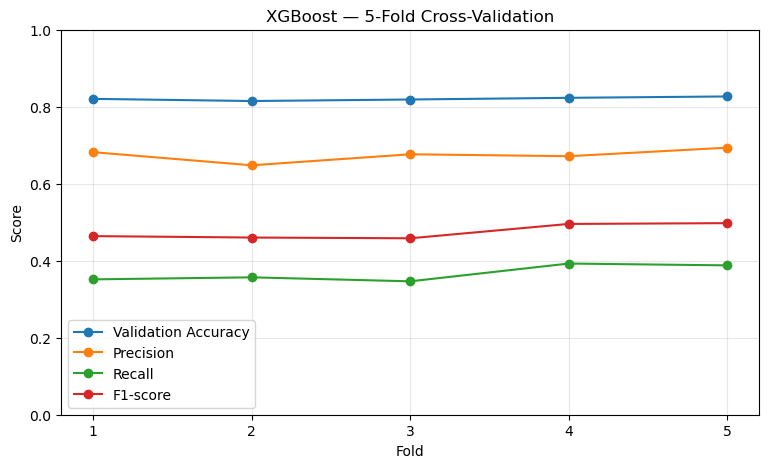

In [68]:

# Plot validation metrics across folds
plt.figure(figsize=(9, 5))

for metric in ["Validation Accuracy", "Precision", "Recall", "F1-score"]:
    plt.plot(
        cv_scores["Fold"],
        cv_scores[metric],
        marker="o",
        label=metric
    )

plt.title("XGBoost — 5-Fold Cross-Validation")
plt.xlabel("Fold")
plt.ylabel("Score")
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 4.21.5 Training vs Validation Accuracy

We compare average training and validation accuracy to detect possible overfitting.

In [69]:

# Calculate average accuracy
mean_train_acc = cv_scores["Train Accuracy"].mean()
mean_val_acc = cv_scores["Validation Accuracy"].mean()

# Calculate generalization gap
accuracy_gap = mean_train_acc - mean_val_acc

print(f"Mean Train Accuracy: {mean_train_acc * 100:.2f}%")
print(f"Mean Validation Accuracy: {mean_val_acc * 100:.2f}%")
print(f"Accuracy Gap: {accuracy_gap * 100:.2f}%")

# Display F1-score stability
print(f"Mean F1-score: {cv_scores['F1-score'].mean():.4f}")
print(f"F1-score Std: {cv_scores['F1-score'].std():.4f}")


Mean Train Accuracy: 83.57%
Mean Validation Accuracy: 82.08%
Accuracy Gap: 1.49%
Mean F1-score: 0.4751
F1-score Std: 0.0197


### 4.22 Model Comparison

We compare all trained classification models to evaluate their predictive performance.

The comparison focuses on training accuracy, test accuracy, Precision, Recall, F1-score, and ROC-AUC.

The objective is to identify a model with good generalization and reliable credit card default prediction.

In [70]:

# Define models for comparison
models = {
    "SGD": sgd_baseline,
    "Random Forest": rf_baseline,
    "XGBoost": xgb_model,
    "XGBoost Random Search": random_search.best_estimator_,
    "XGBoost Grid Search": grid_search.best_estimator_
}

# Collect evaluation results
results = []

for name, model in models.items():

    # Predict training and test data
    y_train_pred = model.predict(X_train_fe)
    y_test_pred = model.predict(X_test_fe)

    # Predict probabilities
    y_test_prob = model.predict_proba(X_test_fe)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_test_prob)
    })

# Create comparison table
all_models_results = pd.DataFrame(results)

display(all_models_results.round(4))


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SGD,0.8072,0.8107,0.6548,0.3044,0.4156,0.7525
1,Random Forest,0.9994,0.8200,0.6610,0.3821,0.4842,0.7673
2,XGBoost,0.8926,0.8170,0.6485,0.3768,0.4766,0.7619
3,XGBoost Random Search,0.8335,0.8205,0.6689,0.3730,0.4790,0.7820
4,XGBoost Grid Search,0.8456,0.8190,0.6617,0.3715,0.4759,0.7783


### Model Selection — Observation

- XGBoost Random Search achieved the highest Test Accuracy (82.05%) and ROC-AUC (0.7820).
- It had the smallest train-test accuracy gap (1.30 percentage points), indicating limited overfitting based on accuracy.
- Its F1-score (0.4790) was close to the highest score achieved by Random Forest (0.4842).
- Random Forest showed substantial overfitting, despite achieving a slightly higher F1-score.

**Conclusion:** XGBoost Random Search is selected as the preferred model because it provides a favorable balance between accuracy, generalization, and classification performance.

### 4.23 Manual Search — `scale_pos_weight`

The parameter `scale_pos_weight` adjusts the importance of the minority class in XGBoost.

We manually test different class weights to improve default prediction.

The objective is to improve Recall and F1-score while maintaining good Accuracy and generalization.

In [71]:

# Calculate class imbalance ratio
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

imbalance_ratio = negative / positive

print(f"Class 0: {negative}")
print(f"Class 1: {positive}")
print(f"Imbalance Ratio: {imbalance_ratio:.2f}")


Class 0: 18691
Class 1: 5309
Imbalance Ratio: 3.52


### 4.23.2 Manual Search — Class Weight Values

We test several `scale_pos_weight` values, starting from 1 (no additional weighting) and increasing toward the class imbalance ratio.

Stratified Cross-Validation is used to compare the models without using the test dataset.

In [72]:

from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Define weights to test
weights = [1, 1.5, 2, 2.5, 3, round(imbalance_ratio, 2), 4]

# Store results
weight_results = []

for weight in weights:

    # Use best Random Search model
    model = clone(random_search.best_estimator_)

    # Set class weight
    model.set_params(
        classifier__scale_pos_weight=weight
    )

    # Evaluate with cross-validation
    scores = cross_validate(
        model,
        X_train_fe,
        y_train,
        cv=cv_5,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1"
        },
        n_jobs=-1
    )

    weight_results.append({
        "scale_pos_weight": weight,
        "CV Accuracy": scores["test_Accuracy"].mean(),
        "CV Precision": scores["test_Precision"].mean(),
        "CV Recall": scores["test_Recall"].mean(),
        "CV F1-score": scores["test_F1"].mean(),
        "F1 Std": scores["test_F1"].std()
    })

# Create comparison table
weight_comparison = pd.DataFrame(weight_results)

display(weight_comparison.round(4))


,scale_pos_weight,CV Accuracy,CV Precision,CV Recall,CV F1-score,F1 Std
0,1.00,0.8208,0.6743,0.3671,0.4751,0.0176
1,1.50,0.8175,0.6213,0.4481,0.5205,0.0128
2,2.00,0.8057,0.5675,0.5118,0.5381,0.0074
3,2.50,0.7912,0.5261,0.5656,0.5451,0.0051
4,3.00,0.7744,0.4920,0.6061,0.5431,0.0047
5,3.52,0.7538,0.4598,0.6440,0.5365,0.0043
6,4.00,0.7353,0.4366,0.6760,0.5305,0.0054


### 4.23.3 Manual Search Visualization

We visualize how Accuracy, Precision, Recall, and F1-score change with different `scale_pos_weight` values.

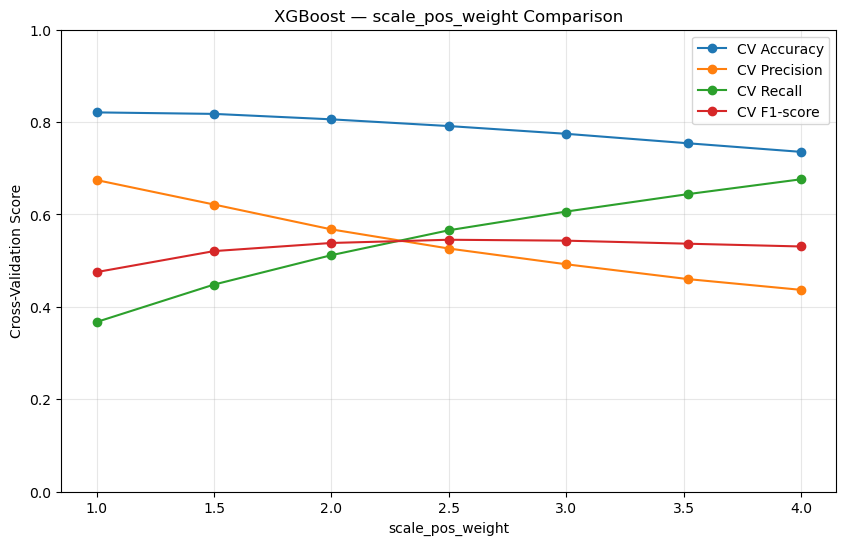

In [73]:

# Plot evaluation metrics
plt.figure(figsize=(10, 6))

for metric in [
    "CV Accuracy",
    "CV Precision",
    "CV Recall",
    "CV F1-score"
]:
    plt.plot(
        weight_comparison["scale_pos_weight"],
        weight_comparison[metric],
        marker="o",
        label=metric
    )

plt.title("XGBoost — scale_pos_weight Comparison")
plt.xlabel("scale_pos_weight")
plt.ylabel("Cross-Validation Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 4.23.4 Select Best Class Weight

We select the class weight with the highest mean cross-validation F1-score.

Accuracy and Recall are also reviewed before confirming the final configuration.

In [74]:

# Select best weight based on CV F1-score
best_row = weight_comparison.loc[
    weight_comparison["CV F1-score"].idxmax()
]

best_weight = best_row["scale_pos_weight"]

print(f"Best scale_pos_weight: {best_weight:.2f}")
print(f"Best CV Accuracy: {best_row['CV Accuracy']:.4f}")
print(f"Best CV Precision: {best_row['CV Precision']:.4f}")
print(f"Best CV Recall: {best_row['CV Recall']:.4f}")
print(f"Best CV F1-score: {best_row['CV F1-score']:.4f}")


Best scale_pos_weight: 2.50
Best CV Accuracy: 0.7912
Best CV Precision: 0.5261
Best CV Recall: 0.5656
Best CV F1-score: 0.5451


### Optimization Metric Comparison

We compare the optimal `scale_pos_weight` values selected by different cross-validation metrics.

This analysis illustrates how the choice of evaluation metric affects class weight selection and the trade-off between Precision and Recall.

In [75]:

# Compare optimal class weights across different metrics
metrics = [
    "CV Accuracy",
    "CV Precision",
    "CV Recall",
    "CV F1-score"
]

best_weights_by_metric = pd.DataFrame([
    {
        "Metric": metric,
        "Best_Weight": weight_comparison.loc[
            weight_comparison[metric].idxmax(),
            "scale_pos_weight"
        ],
        "Best_Score": weight_comparison[metric].max()
    }
    for metric in metrics
])

display(best_weights_by_metric.round(4))


,Metric,Best_Weight,Best_Score
0,CV Accuracy,1.0,0.8208
1,CV Precision,1.0,0.6743
2,CV Recall,4.0,0.6760
3,CV F1-score,2.5,0.5451


**Observation:**

- `scale_pos_weight = 1.0` achieved the highest CV Accuracy (0.8208) and Precision (0.6743).
- `scale_pos_weight = 4.0` achieved the highest CV Recall (0.6760).
- `scale_pos_weight = 2.5` achieved the highest CV F1-score (0.5451).

**Conclusion:** Different optimization metrics favor different class weights. The final weight of 2.5 was selected based on CV F1-score to balance Precision and Recall while supporting early default detection.

### 4.23.5 Train Final Weighted XGBoost Model

We train the selected weighted XGBoost model using the full training dataset.

The model is evaluated on the test dataset to measure its predictive performance.

In [76]:

# Create selected weighted model
xgb_weighted_best = clone(random_search.best_estimator_)

xgb_weighted_best.set_params(
    classifier__scale_pos_weight=best_weight
)

# Train model
xgb_weighted_best.fit(X_train_fe, y_train)

# Predictions
y_pred_train = xgb_weighted_best.predict(X_train_fe)
y_pred_test = xgb_weighted_best.predict(X_test_fe)

# Accuracy
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"\nAccuracy (Train): {acc_train * 100:.2f}%")
print(f"Accuracy (Test): {acc_test * 100:.2f}%")

# Classification Report
print("\nClassification Report (Test):")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=["No Default", "Default"],
    zero_division=0
))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

# ROC-AUC
y_pred_proba = xgb_weighted_best.predict_proba(X_test_fe)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\nROC-AUC (Test): {roc_auc:.4f}")



Accuracy (Train): 81.08%
Accuracy (Test): 78.97%

Classification Report (Test):
              precision    recall  f1-score   support

  No Default       0.87      0.85      0.86      4673
     Default       0.52      0.57      0.55      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.71      0.70      6000
weighted avg       0.80      0.79      0.79      6000

Confusion Matrix:
[[3980  693]
 [ 569  758]]

ROC-AUC (Test): 0.7818


### 4.23.6 Original vs Weighted XGBoost Comparison

We compare the original Random Search XGBoost model with the weighted version.

The objective is to determine whether class weighting improves minority-class detection while maintaining acceptable overall performance.

In [77]:

# Define models
comparison_models = {
    "XGBoost Random Search": random_search.best_estimator_,
    "XGBoost Weighted": xgb_weighted_best
}

# Collect model metrics
comparison_results = []

for name, model in comparison_models.items():

    train_pred = model.predict(X_train_fe)
    test_pred = model.predict(X_test_fe)
    test_prob = model.predict_proba(X_test_fe)[:, 1]

    comparison_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1-score": f1_score(y_test, test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_prob)
    })

# Display comparison
weight_model_comparison = pd.DataFrame(comparison_results)

display(weight_model_comparison.round(4))


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC
0,XGBoost Random Search,0.8335,0.8205,0.6689,0.3730,0.4790,0.7820
1,XGBoost Weighted,0.8108,0.7897,0.5224,0.5712,0.5457,0.7818


### 4.24 Final Model Evaluation — Weighted XGBoost

Weighted XGBoost was selected as the preferred model because it improved the detection of default customers.

We evaluate its final performance using Train Accuracy, Test Accuracy, Precision, Recall, F1-score, and ROC-AUC.

The objective is to assess predictive performance and generalization.

In [78]:

# Select final model
final_model = xgb_weighted_best

# Make predictions
y_train_pred = final_model.predict(X_train_fe)
y_test_pred = final_model.predict(X_test_fe)

# Predict probabilities
y_test_proba = final_model.predict_proba(X_test_fe)[:, 1]

# Calculate metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
auc = roc_auc_score(y_test, y_test_proba)

# Print results
print(f"Accuracy (Train): {train_acc * 100:.2f}%")
print(f"Accuracy (Test): {test_acc * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")


Accuracy (Train): 81.08%
Accuracy (Test): 78.97%
Precision: 0.5224
Recall: 0.5712
F1-score: 0.5457
ROC-AUC: 0.7818


**Observation:**

- Weighted XGBoost achieved 81.08% Train Accuracy and 78.97% Test Accuracy.
- The accuracy gap was 2.11 percentage points, suggesting limited overfitting based on accuracy.
- Recall reached 57.12%, while F1-score improved to 0.5457.
- ROC-AUC was 0.7818, indicating reasonable discrimination between default and non-default customers.

### 4.24.1 Classification Report

The classification report evaluates Precision, Recall, and F1-score for both classes.

We focus particularly on Class 1 (Default), as identifying high-risk customers is the main business objective.

In [79]:

# Display final classification report
print("Classification Report — Weighted XGBoost")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))


Classification Report — Weighted XGBoost
              precision    recall  f1-score   support

  No Default       0.87      0.85      0.86      4673
     Default       0.52      0.57      0.55      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.71      0.70      6000
weighted avg       0.80      0.79      0.79      6000



**Observation:**

- The model identifies approximately 57% of actual default customers.
- Precision for Class 1 is approximately 52%.
- Although some default customers remain undetected, the weighted model improves minority-class detection compared with the original XGBoost Random Search model.

### 4.24.2 Final Model Performance Summary

Weighted XGBoost achieved improved Recall and F1-score compared with the original Random Search model.

Although overall Accuracy decreased, the model identified a larger proportion of default customers while maintaining a relatively small train-test accuracy gap.

**Conclusion:** Weighted XGBoost was selected as the preferred model because it better supports the project's objective of identifying customers at risk of credit card default.

These results are exploratory test-set estimates. Further independent validation would be needed before real-world deployment.

### 4.24.3 Confusion Matrix Analysis — Weighted XGBoost

The confusion matrix evaluates correct and incorrect predictions made by the final model.

We focus on identifying default customers and understanding the trade-off between missed defaults and false alarms.

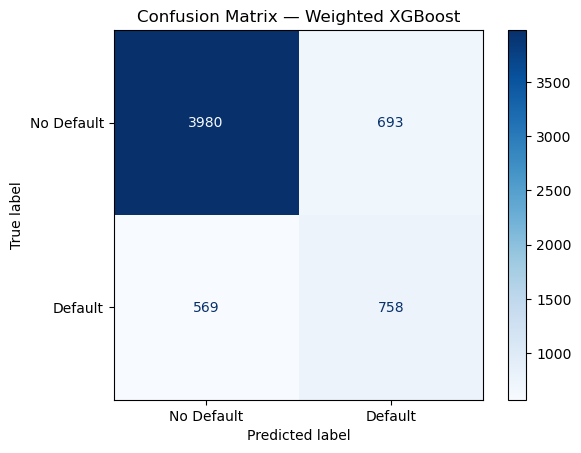

In [80]:

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — Weighted XGBoost")
plt.show()


In [81]:

# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")


True Negatives (TN): 3980
False Positives (FP): 693
False Negatives (FN): 569
True Positives (TP): 758


**Observation:**

- True Positives represent correctly identified default customers.
- False Negatives represent default customers missed by the model.
- False Positives represent non-default customers incorrectly flagged as high-risk.
- Higher Recall improves default detection, but additional false positives may increase review costs.

### 4.25 Default Detection Comparison

We compare the final Weighted XGBoost model with the original Random Search model to evaluate improvements in default detection.

In [82]:

# Get predictions from both models
original_pred = random_search.best_estimator_.predict(X_test_fe)
weighted_pred = final_model.predict(X_test_fe)

# Extract confusion matrix results
comparison = []

for name, predictions in [
    ("Random Search", original_pred),
    ("Weighted XGBoost", weighted_pred)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    comparison.append({
        "Model": name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

# Display comparison
confusion_comparison = pd.DataFrame(comparison)

display(confusion_comparison)


,Model,TP,FP,FN,TN
0,Random Search,495,245,832,4428
1,Weighted XGBoost,758,693,569,3980


**Observation:**

- Random Search achieved higher Accuracy (82.05%) and Precision (66.89%), resulting in fewer false alarms.
- Weighted XGBoost achieved higher Recall (57.12%) and F1-score (0.5457).
- Weighted XGBoost identified 263 additional default customers but generated 448 additional false positives.

**Business Trade-off:**

- If the expected cost of missing a default customer is higher than the cost of reviewing a false alarm, Weighted XGBoost may provide greater business value.
- If the bank has limited resources for risk assessment, Random Search may be more suitable due to fewer false positives.
- Without actual financial loss and review cost data, we cannot determine which model would generate greater cost savings.

**Conclusion:**

Weighted XGBoost is selected as the preferred model because it better supports the project's objective of early credit risk detection. However, the final business decision should consider the trade-off between missed defaults and false alarms.

### 4.26 Weighted XGBoost — Feature Importance

Feature Importance measures the contribution of each feature to the model's predictions.

We extract feature importance scores from the final Weighted XGBoost model to identify the most influential features in credit card default prediction.

In [83]:

# Extract trained XGBoost classifier
xgb_classifier = final_model.named_steps["classifier"]

# Extract fitted preprocessor
fitted_preprocessor = final_model.named_steps["preprocessor"]

# Get feature names after encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance scores
importance_scores = xgb_classifier.feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
display(feature_importance.head(10).round(4))


,Feature,Importance
24,num__max_payment_delay,0.4457
2,num__PAY_0,0.1191
25,num__months_with_delay,0.0691
20,num__avg_bill_amount,0.0233
3,num__PAY_2,0.0199
23,num__credit_utilization,0.0173
36,cat__MARRIAGE_1,0.0155
0,num__LIMIT_BAL,0.0150
21,num__avg_payment_amount,0.0149
8,num__BILL_AMT1,0.0138


### 4.26.1 Top 10 Feature Importance Visualization

We visualize the ten most important features to better understand which customer characteristics contribute most to the model's predictions.

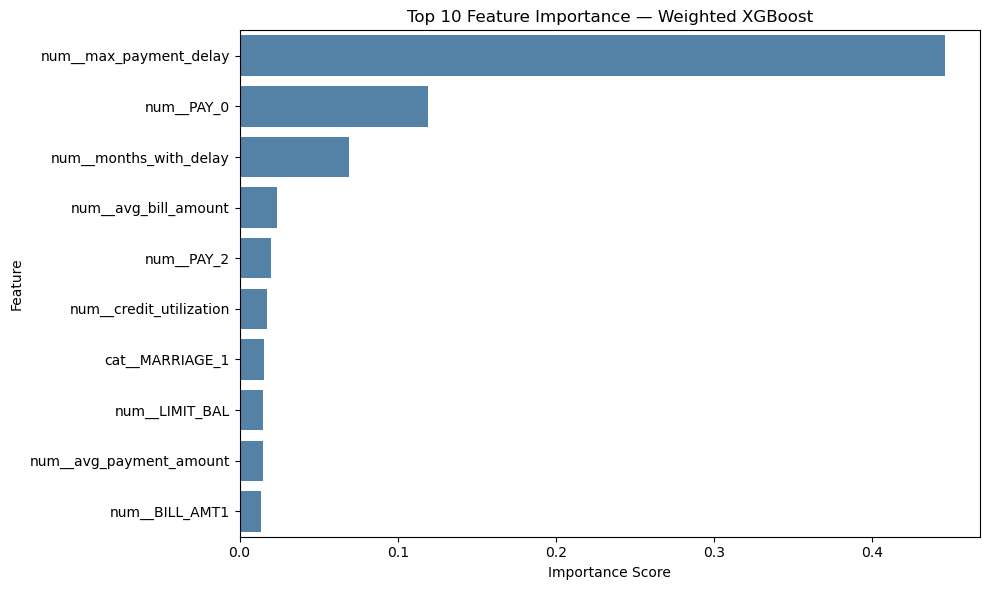

In [84]:

# Select top 10 features
top_10 = feature_importance.head(10)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Feature Importance — Weighted XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


**Observation:**

The chart highlights the ten most important features used by Weighted XGBoost.

Features with higher importance scores have a greater influence on the model's splitting decisions.

These results help identify the main information sources used for credit risk prediction.

### 4.26.2 Feature Importance Interpretation

We interpret the most important features to understand how the model uses customer financial information.

Particular attention is given to repayment history, credit limits, and payment behavior because these variables are relevant to credit risk management.

In [85]:

# Clean feature names for interpretation
feature_importance["Feature"] = (
    feature_importance["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

# Display top 10 important features
display(feature_importance.head(10).round(4))


,Feature,Importance
24,max_payment_delay,0.4457
2,PAY_0,0.1191
25,months_with_delay,0.0691
20,avg_bill_amount,0.0233
3,PAY_2,0.0199
23,credit_utilization,0.0173
36,MARRIAGE_1,0.0155
0,LIMIT_BAL,0.0150
21,avg_payment_amount,0.0149
8,BILL_AMT1,0.0138


**Observation:**

- `max_payment_delay` is the most important feature (0.4457), followed by `PAY_0` (0.1191) and `months_with_delay` (0.0691).
- Repayment history features dominate the ranking, suggesting that payment delays play a major role in the model's predictions.
- Financial features such as `LIMIT_BAL`, `avg_bill_amount`, and `credit_utilization` also contribute, but with lower importance scores.
- Demographic features appear less influential among the top 10 predictors.

**Conclusion:**

The Weighted XGBoost model relies primarily on repayment history to predict credit card default. This supports the project's business objective by highlighting repayment behavior as a key area for credit risk monitoring.

### 4.27 SHAP Analysis — Weighted XGBoost

SHAP (SHapley Additive exPlanations) helps explain how individual features contribute to model predictions.

Unlike Feature Importance, SHAP provides information about both the magnitude and direction of feature contributions.

We use SHAP to understand which customer characteristics increase or decrease predicted credit default risk.

In [86]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [87]:

import shap

# Extract trained model and preprocessor
xgb_classifier = final_model.named_steps["classifier"]
fitted_preprocessor = final_model.named_steps["preprocessor"]

# Sample training data
X_shap_sample = X_train_fe.sample(
    n=min(500, len(X_train_fe)),
    random_state=SEED
)

# Apply fitted preprocessing
X_shap = fitted_preprocessor.transform(X_shap_sample)

# Convert sparse matrix to dense
if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

# Get encoded feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Create DataFrame
X_shap_df = pd.DataFrame(
    X_shap,
    columns=feature_names,
    index=X_shap_sample.index
)

print("SHAP data shape:", X_shap_df.shape)


SHAP data shape: (500, 39)


**Observation:**

A sample of 500 training records was prepared using the fitted preprocessing pipeline.

The transformed dataset contains numerical and encoded categorical features ready for SHAP analysis.

### 4.27.1 Calculate SHAP Values

We use TreeExplainer to calculate SHAP values for the trained Weighted XGBoost model.

Positive SHAP values increase the model's predicted default score, while negative values decrease it.

In [88]:

# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values
shap_values = explainer(X_shap_df)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)


SHAP values calculated successfully.
SHAP values shape: (500, 39)


### 4.27.2 SHAP Summary Plot

The SHAP Summary Plot displays the impact of features across multiple customers.

It shows which features have the greatest influence and whether high or low feature values increase predicted default risk.

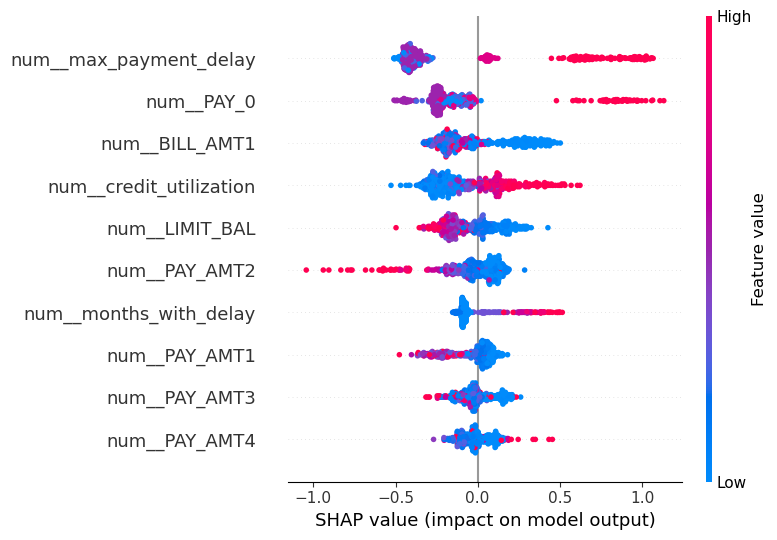

In [89]:

# Plot SHAP summary
shap.summary_plot(
    shap_values.values,
    X_shap_df,
    max_display=10,
    show=True
)


**Observation:**

- `max_payment_delay` and `PAY_0` show the strongest impact on model predictions.
- Higher repayment delays and credit utilization generally increase predicted default risk.
- Higher credit limits and previous payment amounts tend to reduce the predicted default score.
- Bill amounts show more complex patterns, suggesting a nonlinear relationship with default risk.

**Conclusion:** Repayment behavior is a major driver of the model's default predictions.

### 4.27.3 SHAP Global Feature Importance

We use a SHAP bar plot to rank features based on their average absolute contribution to model predictions.

This provides an additional perspective on Feature Importance.

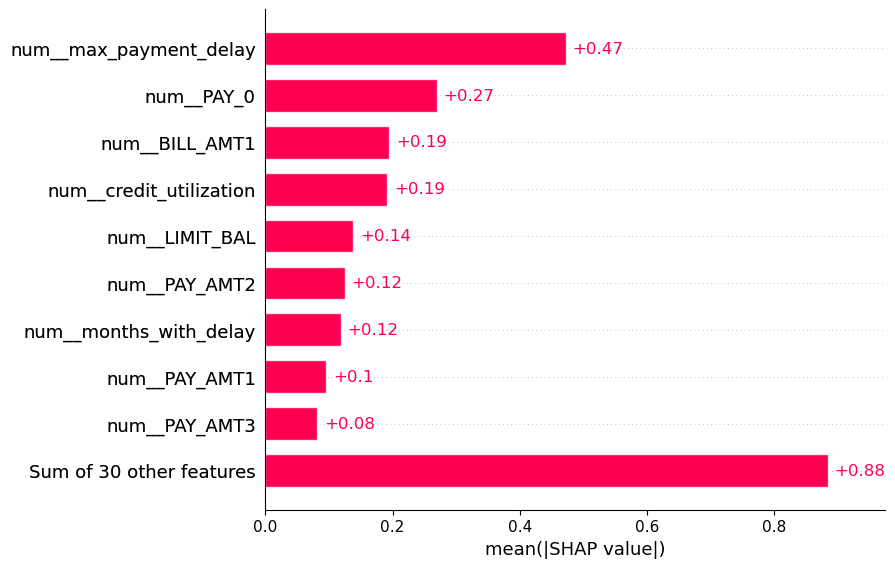

In [90]:

# Plot global SHAP importance
shap.plots.bar(
    shap_values,
    max_display=10,
    show=True
)


**Observation:**

- `max_payment_delay` has the highest average absolute SHAP value (0.47), followed by `PAY_0` (0.27).
- `BILL_AMT1` and `credit_utilization` also have significant contributions (approximately 0.19 each).
- The SHAP ranking differs slightly from XGBoost's built-in Feature Importance.

**Conclusion:** Repayment history remains the most influential feature group, while bill amounts and credit utilization also contribute meaningfully to predictions.

### 4.27.4 SHAP Dependence — Maximum Payment Delay

We examine `max_payment_delay`, the most important feature identified by XGBoost Feature Importance.

The dependence plot shows how different repayment delay values relate to their SHAP contributions.

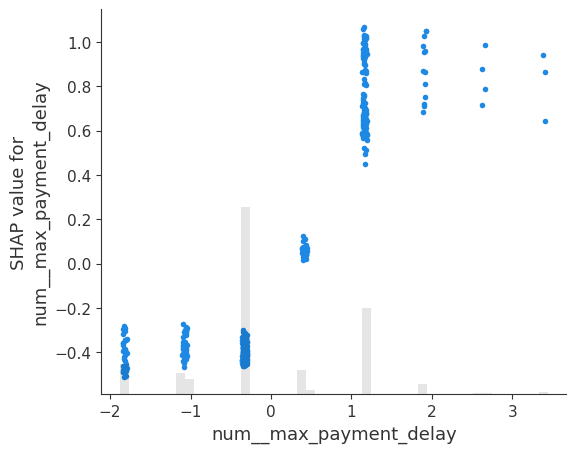

In [91]:

# Find encoded feature name
delay_feature = next(
    col for col in X_shap_df.columns
    if col.endswith("max_payment_delay")
)

# Plot SHAP dependence
shap.plots.scatter(
    shap_values[:, delay_feature],
    show=True
)


**Observation:**

- Lower values of `max_payment_delay` generally have negative SHAP contributions.
- Higher repayment delay values show strong positive SHAP contributions, sometimes exceeding 1.0.
- The relationship is nonlinear, with a noticeable increase in predicted default risk at higher delay levels.

**Conclusion:** Severe repayment delays strongly increase the model's predicted default score, highlighting the importance of repayment history in credit risk monitoring.

### 4.27.5 SHAP Waterfall Plot — Individual Customer

We use a SHAP Waterfall Plot to explain one customer's predicted default risk.

The plot shows how individual features move the prediction away from the model's baseline output.

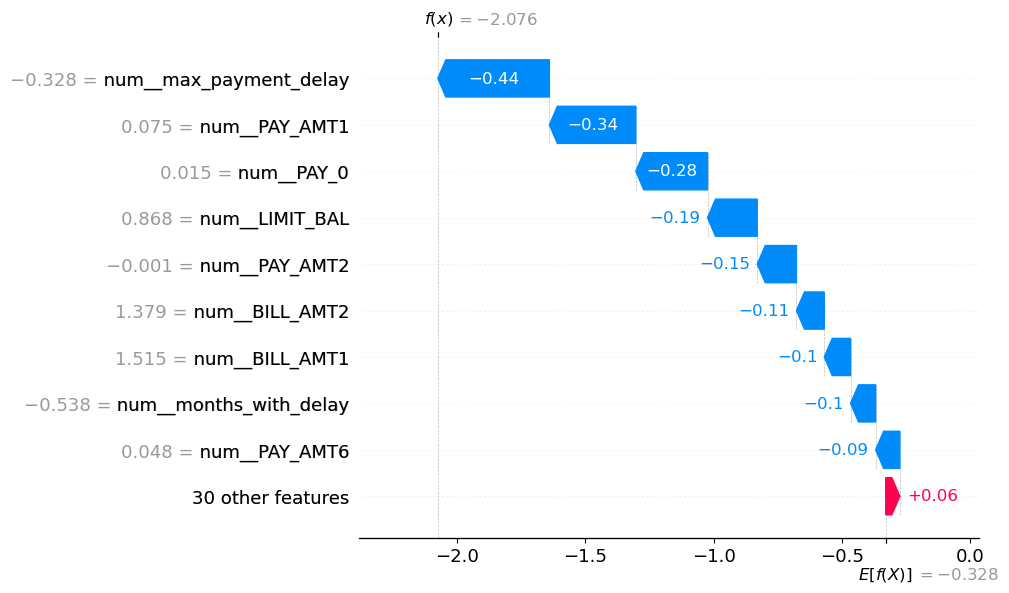

Predicted Default Probability: 0.1114


In [92]:

# Select one customer
customer_index = 0

# Plot individual prediction
shap.plots.waterfall(
    shap_values[customer_index],
    max_display=10,
    show=True
)

# Display predicted default probability
customer_proba = xgb_classifier.predict_proba(
    X_shap_df.iloc[[customer_index]]
)[0, 1]

print(f"Predicted Default Probability: {customer_proba:.4f}")


**Observation:**

- For the selected customer, the model output decreases from the baseline value of -0.328 to -2.076.
- `max_payment_delay` (-0.44), `PAY_AMT1` (-0.34), and `PAY_0` (-0.28) make the largest negative contributions.
- These features reduce the predicted default score for this customer.

**Conclusion:** The individual explanation illustrates how repayment history and payment behavior can lower a customer's predicted default risk.

### 4.27.6 SHAP Analysis — Conclusion

SHAP analysis confirms that repayment history is a major contributor to Weighted XGBoost predictions.

Higher repayment delays and credit utilization generally increase the predicted default score, while higher credit limits and previous payments tend to reduce it.

The analysis also reveals nonlinear relationships and provides explanations for individual customer predictions.

**Business Value:** SHAP improves model transparency and helps banks understand the main patterns used to identify customers at risk of credit card default.

However, these explanations describe model behavior and do not establish causal relationships.

## STEP 5 Final Machine Learning Conclusion & Limitations

### Machine Learning Conclusion

This project developed and compared three classification algorithms: SGD, Random Forest, and XGBoost, to predict credit card default.

Hyperparameter tuning was performed using Random Search and Grid Search. Class imbalance was addressed using `scale_pos_weight`, and Weighted XGBoost was selected as the preferred final model.

**Final Model Performance:**

| Metric | Weighted XGBoost |
|---|---:|
| Train Accuracy | 81.08% |
| Test Accuracy | 78.97% |
| Precision | 52.24% |
| Recall | 57.12% |
| F1-score | 0.5457 |
| ROC-AUC | 0.7818 |

Compared with the original XGBoost Random Search model, Weighted XGBoost improved Recall from 37.30% to 57.12% and F1-score from 0.4790 to 0.5457.

SHAP analysis identified repayment history, particularly `max_payment_delay` and `PAY_0`, as major contributors to model predictions.

**Conclusion:** Weighted XGBoost improved the detection of actual default customers and provided interpretable predictions through SHAP analysis. However, further validation and financial cost assessment are required before real-world deployment.

### 5.5.1 Model Limitations

Despite the improvements, the final model has several limitations:

- **Moderate Recall:** Approximately 42.88% of actual default customers remain unidentified.
- **False Positives:** The weighted model incorrectly classified 693 non-default customers as high-risk.
- **Accuracy Trade-off:** Test Accuracy decreased from 82.05% to 78.97% after class weighting.
- **Historical Data:** The dataset represents historical credit card customers and may not reflect current customer behavior.
- **Generalization:** A small train-test accuracy gap does not guarantee the absence of underfitting or overfitting. Repeated test-set comparisons also limit the independence of the reported evaluation.
- **Fairness:** Demographic variables require careful evaluation to avoid unfair or discriminatory predictions.

These limitations should be considered before applying the model in a real banking environment.

## Step 6 — Business Impact Analysis

### 6.1 Business Objective

The main business objective is to help banks identify customers at risk of credit card default before the following month's payment.

Early risk detection may help financial institutions improve risk monitoring, prioritize customer reviews, and take appropriate preventive actions.

### 6.2 Impact on Default Detection

The final Weighted XGBoost model improved the identification of actual default customers compared with the original Random Search model.

| Business Metric | Random Search | Weighted XGBoost |
|---|---:|---:|
| Correctly Identified Defaults (TP) | 495 | 758 |
| Missed Defaults (FN) | 832 | 569 |
| False Alarms (FP) | 245 | 693 |
| Recall | 37.30% | 57.12% |

**Observation:**

- Weighted XGBoost identified 263 additional default customers in the test dataset.
- Missed defaults decreased by 263 cases.
- However, false alarms increased by 448 cases.

**Business Impact:** Higher Recall could help banks identify more potentially high-risk customers for early review and support.

### 6.3 Business Cost Trade-off

Selecting the best model depends on the relative costs of missed defaults and false alarms.

- **False Negatives:** Missing a customer who later defaults may result in financial losses.
- **False Positives:** Incorrectly flagging a non-default customer may increase review costs and create unnecessary customer interventions.

If the expected cost of missing a default customer is higher than the cost of reviewing a false alarm, Weighted XGBoost may provide greater business value.

If the bank has limited resources for risk assessment, Random Search may be more suitable because it generates fewer false positives.

**Conclusion:** Without actual financial loss and review cost data, we cannot determine which model would generate greater cost savings.

### 6.4 Potential Business Applications

The model could support banks in several ways:

1. **Early Risk Detection:** Identify customers with a higher predicted probability of default.
2. **Risk Monitoring:** Use repayment history and payment behavior to monitor potential credit risk.
3. **Customer Support:** Prioritize appropriate payment reminders or financial assistance.
4. **Decision Support:** Provide interpretable risk predictions to assist human risk assessment teams.

SHAP explanations can help analysts understand the factors influencing individual predictions.

**Conclusion:** The model offers a potential decision-support tool for credit risk management, rather than a replacement for human judgment.

### 6.5 Business Impact Conclusion

Weighted XGBoost improved the early identification of potential credit card defaults.

The model detected 263 additional default customers compared with the original Random Search model, although this improvement resulted in more false positives.

SHAP analysis provided further insights into the role of repayment delays, credit limits, and payment behavior.

**Conclusion:** The project supports its business objective by demonstrating how machine learning can improve credit risk detection and provide interpretable information for banking decisions. However, real financial benefits require further evaluation using operational cost data.

### 6.6 Business Cost Simulation

The objective of this simulation is to compare the potential business costs associated with Random Search XGBoost and Weighted XGBoost.

Two types of prediction errors are considered:

- **False Negative (FN):** A customer who actually defaults but is not identified by the model. This may lead to financial losses.
- **False Positive (FP):** A customer who does not default but is incorrectly flagged as high-risk. This may generate additional review costs.

The simulation uses actual confusion matrix results from the test dataset and hypothetical financial costs.

**Total Estimated Error Cost = (FN × Cost per FN) + (FP × Cost per FP)**

The costs are illustrative assumptions, not actual banking expenses.

### 6.6.1 Define Cost Assumptions

In [93]:

# Hypothetical business costs in EUR
cost_fn = 1000
cost_fp = 50

# Confusion matrix results from the test set
business_results = pd.DataFrame({
    "Model": ["Random Search XGBoost", "Weighted XGBoost"],
    "False_Negatives": [832, 569],
    "False_Positives": [245, 693],
    "True_Positives": [495, 758]
})

# Calculate estimated business costs
business_results["FN_Cost"] = business_results["False_Negatives"] * cost_fn
business_results["FP_Cost"] = business_results["False_Positives"] * cost_fp

business_results["Total_Estimated_Cost"] = (
    business_results["FN_Cost"] + business_results["FP_Cost"]
)

display(business_results)


,Model,False_Negatives,False_Positives,True_Positives,FN_Cost,FP_Cost,Total_Estimated_Cost
0,Random Search XGBoost,832,245,495,832000,12250,844250
1,Weighted XGBoost,569,693,758,569000,34650,603650


### 6.6.2 Estimated Cost Comparison

Using hypothetical costs of €1,000 per missed default and €50 per false alarm, the estimated total error costs of both models are compared.

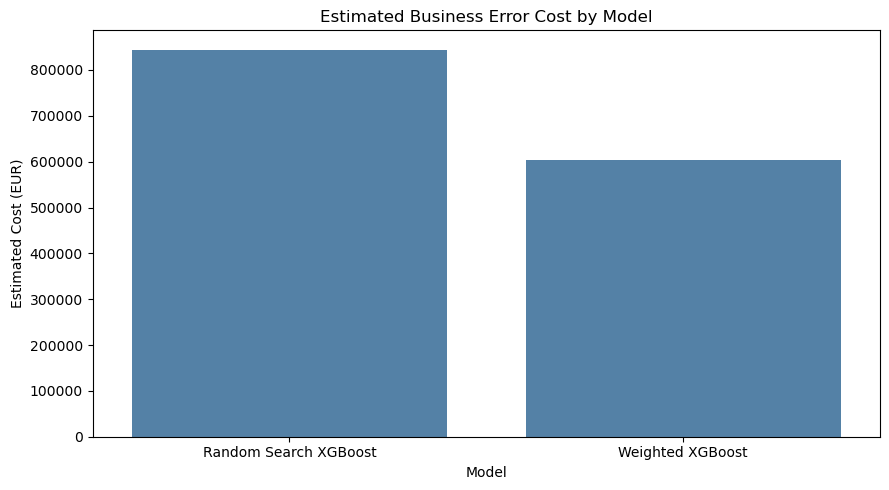

Random Search Estimated Cost: €844,250
Weighted XGBoost Estimated Cost: €603,650
Estimated Cost Difference: €240,600


In [94]:

# Visualize estimated error costs
plt.figure(figsize=(9, 5))

sns.barplot(
    data=business_results,
    x="Model",
    y="Total_Estimated_Cost",
    color="steelblue"
)

plt.title("Estimated Business Error Cost by Model")
plt.xlabel("Model")
plt.ylabel("Estimated Cost (EUR)")
plt.tight_layout()
plt.show()

# Compare estimated costs
random_cost = business_results.loc[
    business_results["Model"] == "Random Search XGBoost",
    "Total_Estimated_Cost"
].iloc[0]

weighted_cost = business_results.loc[
    business_results["Model"] == "Weighted XGBoost",
    "Total_Estimated_Cost"
].iloc[0]

print(f"Random Search Estimated Cost: €{random_cost:,.0f}")
print(f"Weighted XGBoost Estimated Cost: €{weighted_cost:,.0f}")
print(f"Estimated Cost Difference: €{random_cost - weighted_cost:,.0f}")


**Observation:**

- Random Search XGBoost generates an estimated error cost of €844,250.
- Weighted XGBoost generates a lower estimated error cost of €603,650.
- Under these hypothetical assumptions, Weighted XGBoost reduces estimated error costs by €240,600.

**Conclusion:** When missed defaults are substantially more expensive than false alarms, Weighted XGBoost may offer greater business value despite generating more false positives.

### 6.6.3 Sensitivity Analysis — Different Cost Scenarios

Since actual banking costs are unavailable, we evaluate three hypothetical scenarios.

This analysis examines how the preferred model changes depending on the relative costs of missed defaults and false alarms.

,Scenario,Cost_FN,Cost_FP,Random_Search_Cost,Weighted_XGBoost_Cost
0,Low FN Cost,100,100,107700,126200
1,Moderate FN Cost,500,100,440500,353800
2,High FN Cost,1000,50,844250,603650


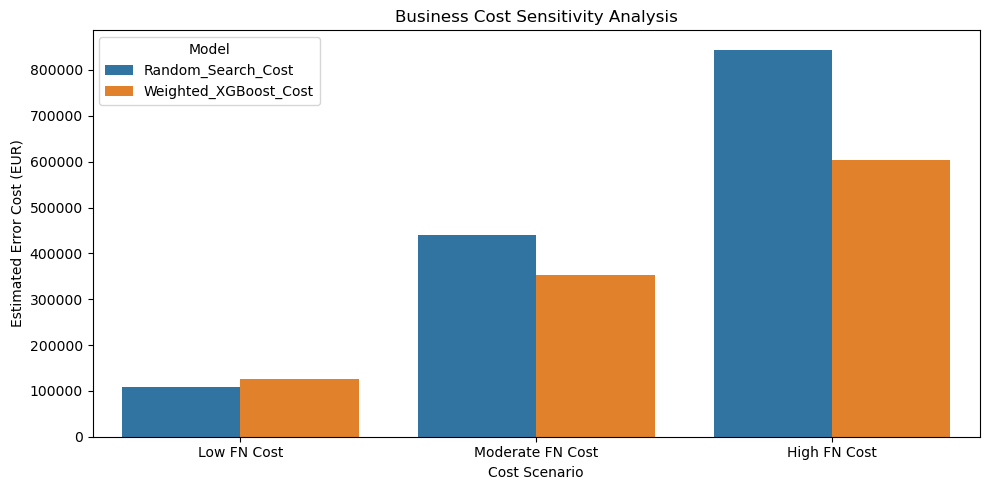

In [95]:

# Define three hypothetical cost scenarios
cost_scenarios = pd.DataFrame({
    "Scenario": [
        "Low FN Cost",
        "Moderate FN Cost",
        "High FN Cost"
    ],
    "Cost_FN": [100, 500, 1000],
    "Cost_FP": [100, 100, 50]
})

# Calculate total estimated costs for each model
cost_scenarios["Random_Search_Cost"] = (
    832 * cost_scenarios["Cost_FN"]
    + 245 * cost_scenarios["Cost_FP"]
)

cost_scenarios["Weighted_XGBoost_Cost"] = (
    569 * cost_scenarios["Cost_FN"]
    + 693 * cost_scenarios["Cost_FP"]
)

display(cost_scenarios)

# Visualize sensitivity analysis
cost_plot = cost_scenarios.melt(
    id_vars="Scenario",
    value_vars=["Random_Search_Cost", "Weighted_XGBoost_Cost"],
    var_name="Model",
    value_name="Estimated_Cost"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=cost_plot,
    x="Scenario",
    y="Estimated_Cost",
    hue="Model"
)

plt.title("Business Cost Sensitivity Analysis")
plt.xlabel("Cost Scenario")
plt.ylabel("Estimated Error Cost (EUR)")
plt.tight_layout()
plt.show()


**Observation:**

- When missed defaults and false alarms have equal unit costs, Random Search produces a lower estimated total cost.
- As the cost of missed defaults increases, Weighted XGBoost becomes more cost-effective in the simulation.
- Model selection depends on business priorities and the relative costs of prediction errors.

**Conclusion:** The model with the highest classification accuracy is not necessarily the model with the lowest estimated business cost.

### 6.6.4 Break-Even Cost Analysis

In [96]:

# Calculate break-even cost ratio
fn_reduction = 832 - 569
fp_increase = 693 - 245

break_even_ratio = fp_increase / fn_reduction

print(f"Additional defaults detected: {fn_reduction}")
print(f"Additional false alarms: {fp_increase}")
print(f"Break-even FN/FP cost ratio: {break_even_ratio:.2f}")


Additional defaults detected: 263
Additional false alarms: 448
Break-even FN/FP cost ratio: 1.70


**Observation:**

The break-even cost ratio is approximately 1.70.

Under this simplified cost model:

- If the cost of one missed default exceeds 1.70 times the cost of one false alarm, Weighted XGBoost has a lower estimated total error cost.
- If the ratio is below 1.70, Random Search has a lower estimated total error cost.

**Conclusion:** The preferred model depends on the bank's actual error costs rather than predictive performance alone.

### 6.6.5 Business Cost Simulation — Conclusion

The simulation demonstrates how machine learning predictions can support cost-sensitive credit risk decisions.

Weighted XGBoost identifies more actual default customers but also generates more false positives.

Under scenarios where missed defaults are relatively expensive, Weighted XGBoost produces a lower estimated error cost. However, Random Search may be preferable when false alarms are costly.

**Business Conclusion:** Weighted XGBoost remains the preferred model for the project's early risk detection objective, but its financial advantage depends on the bank's actual financial and operational costs.

**Simulation Limitations:**

- The assumed cost of €1,000 per missed default is hypothetical and does not imply that every missed default could have been prevented through banking intervention.
- The estimated cost differences represent simulated prediction error costs, not actual reductions in financial losses or proven bank savings.
- The simulation is based on 6,000 customers in the test dataset. Its results should not be directly extrapolated to the bank's entire customer population or annual financial performance.
- Real-world financial impact would require actual loss data, operational costs, and evidence of intervention effectiveness.

### 6.7 Risk Review Capacity Simulation

Banks may have limited resources to review customers identified as potentially high-risk.

This simulation evaluates how many actual default customers can be identified when a risk management team reviews only a limited number of customers.

Using the final Weighted XGBoost model, customers are ranked by their predicted default probability, from highest to lowest.

We evaluate different review capacities using the 6,000 customers in the test dataset.

**Business Objective:** To understand how risk-based customer prioritization can support efficient allocation of limited review resources.

### 6.7.1 Prepare Customer Risk Ranking

In [97]:

# Predict default probabilities using the final model
risk_probabilities = final_model.predict_proba(X_test_fe)[:, 1]

# Create a test customer risk table
risk_ranking = pd.DataFrame({
    "Actual_Default": np.asarray(y_test),
    "Predicted_Default_Probability": risk_probabilities
}, index=X_test_fe.index)

# Rank customers from highest to lowest predicted risk
risk_ranking = risk_ranking.sort_values(
    by="Predicted_Default_Probability",
    ascending=False
).reset_index(drop=True)

# Assign review priority
risk_ranking["Risk_Rank"] = np.arange(1, len(risk_ranking) + 1)

display(risk_ranking.head(10))


,Actual_Default,Predicted_Default_Probability,Risk_Rank
0,1,0.965992,1
1,1,0.956772,2
2,0,0.956693,3
3,1,0.956547,4
4,0,0.955319,5
5,1,0.953387,6
6,1,0.949205,7
7,1,0.945444,8
8,0,0.942733,9
9,1,0.940881,10


**Observation:**

Customers are ranked according to their predicted probability of default.

Higher-ranked customers are prioritized for risk review because they receive higher predicted default scores from the Weighted XGBoost model.

This ranking provides a basis for evaluating different review capacity scenarios.

### 6.7.2 Review Capacity - Simulate Different Scenarios

We simulate five review capacities: 100, 300, 500, 1,000, and 1,500 customers.

For each scenario, we select the customers with the highest predicted default probabilities and calculate:

- **Defaults Identified:** Number of actual default customers in the selected group.
- **Precision at N:** Percentage of selected customers who actually defaulted.
- **Recall at N:** Percentage of all actual defaults captured within the selected group.

These metrics help assess the effectiveness of risk-based prioritization under limited review capacity.


In [98]:

# Define hypothetical monthly review capacities
review_capacities = [100, 300, 500, 1000, 1500]

# Total actual defaults in the test set
total_defaults = int(risk_ranking["Actual_Default"].sum())

# Calculate results for each review capacity
capacity_results = []

for capacity in review_capacities:
    top_customers = risk_ranking.head(capacity)

    defaults_identified = int(top_customers["Actual_Default"].sum())
    non_defaults_reviewed = capacity - defaults_identified

    precision_at_n = defaults_identified / capacity
    recall_at_n = defaults_identified / total_defaults

    capacity_results.append({
        "Review_Capacity": capacity,
        "Defaults_Identified": defaults_identified,
        "Non_Defaults_Reviewed": non_defaults_reviewed,
        "Precision_at_N": precision_at_n,
        "Recall_at_N": recall_at_n
    })

capacity_results = pd.DataFrame(capacity_results)

# Display simulation results
display(capacity_results.round(4))


,Review_Capacity,Defaults_Identified,Non_Defaults_Reviewed,Precision_at_N,Recall_at_N
0,100,84,16,0.840,0.0633
1,300,231,69,0.770,0.1741
2,500,361,139,0.722,0.2720
3,1000,606,394,0.606,0.4567
4,1500,771,729,0.514,0.5810


**Observation:**

- Reviewing the top 100 highest-risk customers identifies 84 actual defaults, achieving 84% Precision at N.
- With a review capacity of 500 customers, the model identifies 361 actual defaults, covering 27.20% of all defaults.
- Reviewing 1,000 customers identifies 606 defaults, achieving 45.67% Recall at N.
- As review capacity increases, more defaults are identified, while Precision at N gradually decreases.

**Conclusion:** Risk-based ranking allows banks to prioritize customers with higher predicted default risk, helping allocate limited review resources more effectively.

### 6.7.3 Visualize Review Capacity vs Default Detection

We visualize the number of actual defaults identified at different review capacities.

The model-based ranking is compared with the expected number of defaults under random customer selection.

This comparison illustrates whether model-based prioritization is more effective than selecting customers without risk information.


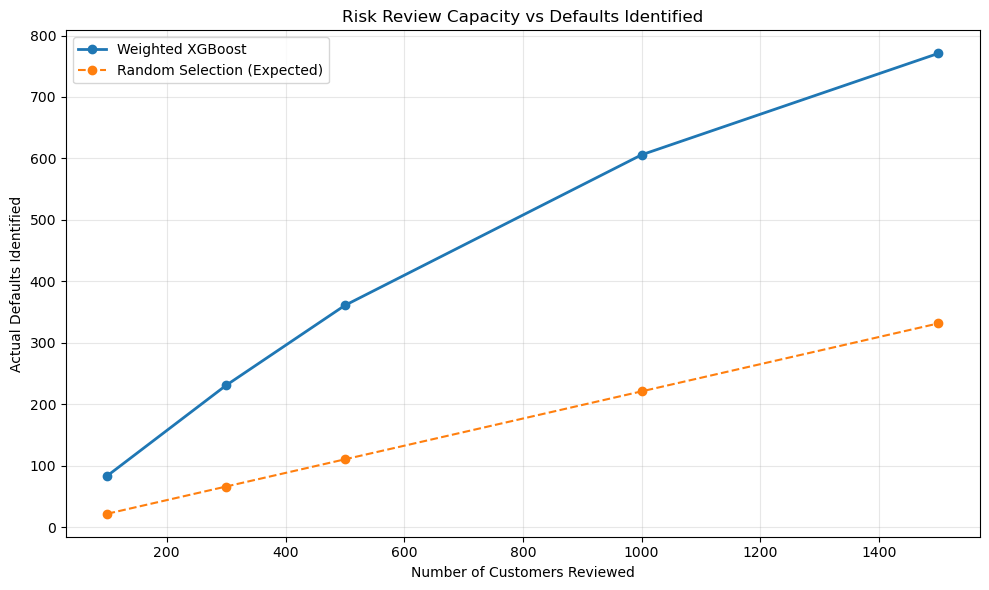

In [99]:

# Calculate expected defaults under random selection
default_rate = total_defaults / len(risk_ranking)

capacity_results["Random_Expected_Defaults"] = (
    capacity_results["Review_Capacity"] * default_rate
)

# Plot review capacity against defaults identified
plt.figure(figsize=(10, 6))

plt.plot(
    capacity_results["Review_Capacity"],
    capacity_results["Defaults_Identified"],
    marker="o",
    linewidth=2,
    label="Weighted XGBoost"
)

plt.plot(
    capacity_results["Review_Capacity"],
    capacity_results["Random_Expected_Defaults"],
    marker="o",
    linestyle="--",
    label="Random Selection (Expected)"
)

plt.title("Risk Review Capacity vs Defaults Identified")
plt.xlabel("Number of Customers Reviewed")
plt.ylabel("Actual Defaults Identified")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Observation:**

- Weighted XGBoost consistently identifies more actual defaults than the expected random selection baseline across all five review capacities.
- When reviewing 500 customers, the model identifies 361 actual defaults, compared with approximately 111 expected under random selection.
- At a review capacity of 1,000, the model identifies 606 defaults, compared with approximately 221 expected under random selection.
- The gap demonstrates that model-based ranking concentrates more actual default customers among those selected for review.

**Conclusion:** Risk-based customer prioritization is more effective than random selection at identifying actual defaults within the simulated review capacities.

### 6.7.4 Risk Review Capacity Simulation — Conclusion

The simulation demonstrates how Weighted XGBoost can support customer risk prioritization under limited review resources.

When reviewing the 500 highest-risk customers, the model identifies 361 actual defaults, compared with approximately 111 expected under random selection.

Increasing review capacity improves default detection coverage but reduces Precision at N, highlighting the trade-off between operational resources and risk identification.

**Business Conclusion:** Model-based risk ranking may help banks allocate review resources more effectively and identify more potentially high-risk customers than random selection.

However, the analysis is based on 6,000 historical test customers. Identifying actual defaults does not guarantee that these defaults could have been prevented, and real operational benefits require further validation.

### 6.8 Risk Segmentation & Cost Optimization Simulation

This simulation explores how banks could use Weighted XGBoost risk scores to classify customers into three risk levels: Low, Medium, and High.

Instead of applying the same review process to every customer, the bank could allocate different levels of attention according to predicted risk.

**Business Objectives:**

- Identify customer groups with different levels of default risk.
- Prioritize high-risk customers for manual review.
- Reduce unnecessary operational costs through differentiated review strategies.
- Evaluate the trade-off between review costs and missed defaults.

The analysis uses 6,000 historical test customers. Risk thresholds and intervention costs are hypothetical and intended for simulation purposes only.

### 6.8.1 Create Risk Segmentation

Customers are divided into three risk categories using their predicted default risk score**Low Risk:** Score below 0.30.

- **Medium Risk:** Score from 0.30 to below 0.60.
- **High Risk:** Score of 0.60 or above.

These thresholds are illustrative and have not been optimized or validated for real-world banking decisions.



In [100]:

# Use the existing final model
risk_scores = final_model.predict_proba(X_test_fe)[:, 1]

# Create a risk segmentation table
risk_segments = pd.DataFrame({
    "Actual_Default": np.asarray(y_test),
    "Risk_Score": risk_scores
}, index=X_test_fe.index)

# Assign risk levels using illustrative thresholds
risk_segments["Risk_Level"] = pd.cut(
    risk_segments["Risk_Score"],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

# Display first 10 customers
display(risk_segments.head(10))


,Actual_Default,Risk_Score,Risk_Level
24380,0,0.135600,Low
2508,0,0.235890,Low
10431,1,0.174626,Low
24017,0,0.181031,Low
11286,0,0.476424,Medium
20923,0,0.247055,Low
29668,1,0.771958,High
26712,0,0.911491,High
19992,0,0.213843,Low
9898,0,0.264768,Low


**Observation:**

Customers are assigned to Low, Medium, and High risk categories based on the final model's predicted risk scores.

This segmentation allows different operational strategies to be considered for each risk group.

The thresholds are hypothetical and require further validation before practical use.

### 6.8.2 Risk Group Performance

We evaluate the number of customers, actual defaults, and observed default rates within each risk category.

The objective is to determine whether higher predicted risk scores correspond to higher observed default rates.

In [101]:

# Summarize actual default outcomes by risk group
risk_summary = (
    risk_segments
    .groupby("Risk_Level", observed=False)
    .agg(
        Customers=("Actual_Default", "size"),
        Actual_Defaults=("Actual_Default", "sum")
    )
    .reset_index()
)

# Calculate non-defaults and observed default rate
risk_summary["Non_Defaults"] = (
    risk_summary["Customers"] - risk_summary["Actual_Defaults"]
)

risk_summary["Default_Rate"] = (
    risk_summary["Actual_Defaults"] / risk_summary["Customers"]
)

risk_summary["Customer_Share"] = (
    risk_summary["Customers"] / len(risk_segments)
)

display(risk_summary.round(4))

# Verify that all customers are included
print("Total customers:", risk_summary["Customers"].sum())
print("Total actual defaults:", risk_summary["Actual_Defaults"].sum())


,Risk_Level,Customers,Actual_Defaults,Non_Defaults,Default_Rate,Customer_Share
0,Low,3063,287,2776,0.0937,0.5105
1,Medium,1902,414,1488,0.2177,0.3170
2,High,1035,626,409,0.6048,0.1725


Total customers: 6000
Total actual defaults: 1327


**Observation:**

- **Low Risk:** 3,063 customers (51.05%) have an observed default rate of 9.37%.
- **Medium Risk:** 1,902 customers (31.70%) have an observed default rate of 21.77%.
- **High Risk:** 1,035 customers (17.25%) have an observed default rate of 60.48%.
- The observed default rate increases significantly across the three risk levels, indicating that the model effectively separates customers with different levels of default risk.

**Business Conclusion:**

The High Risk group represents only 17.25% of customers but contains 626 actual defaults, approximately 47.17% of all defaults in the test dataset.

This suggests that risk segmentation could help banks prioritize high-risk customers for manual review while applying lower-cost monitoring strategies to other groups.

### 6.8.3 Risk Segmentation Visualization

We visualize customer distribution and observed default rates across the three risk levels.

These charts help assess the potential review workload and the effectiveness of risk segmentation.

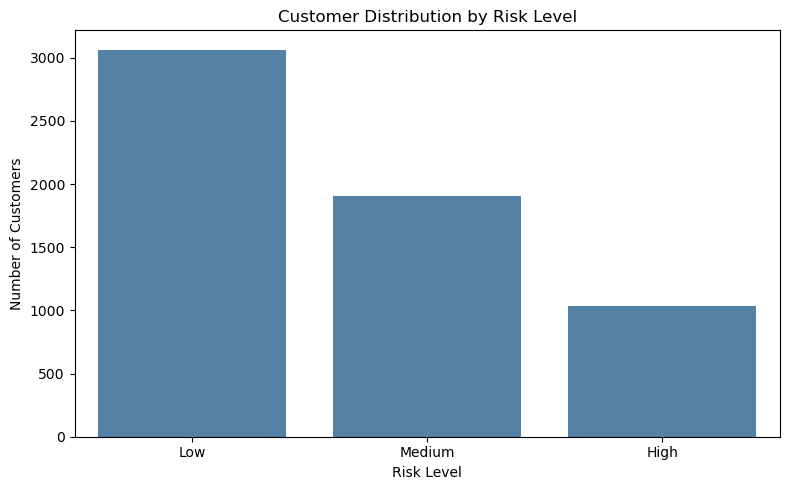

In [102]:

# Visualize customer distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_summary,
    x="Risk_Level",
    y="Customers",
    color="steelblue"
)

plt.title("Customer Distribution by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


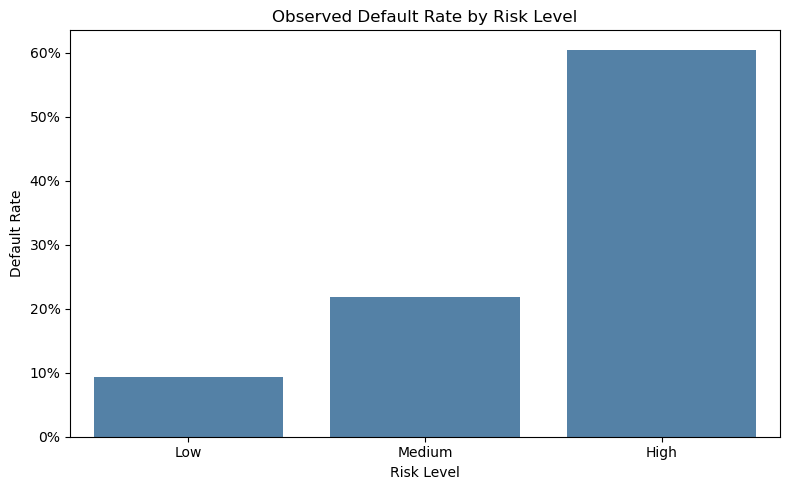

In [103]:

# Visualize observed default rates
plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_summary,
    x="Risk_Level",
    y="Default_Rate",
    color="steelblue"
)

plt.title("Observed Default Rate by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Default Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)
plt.tight_layout()
plt.show()


**Observation:**

- **Low Risk:** 51.05% of customers belong to this group, with an observed default rate of 9.37%.
- **Medium Risk:** 31.70% of customers have an observed default rate of 21.77%.
- **High Risk:** Only 17.25% of customers are classified as high-risk, but their observed default rate reaches 60.48%.
- The increasing default rates across risk levels demonstrate that the model effectively distinguishes between different levels of credit default risk.

**Business Conclusion:**

The High Risk group contains 626 actual defaults, representing approximately 47.17% of all defaults in the test dataset.

This suggests that banks could prioritize manual reviews for a relatively small group of high-risk customers while applying lower-cost monitoring strategies to other customers.

However, risk segmentation does not eliminate prediction errors, and its financial benefits require further validation.

### 6.8.4 Tiered Intervention Cost Simulation

We compare three hypothetical customer risk management strategies:

- **Strategy A — No Additional Intervention:** No additional risk review or reminders.
- **Strategy B — Review All Flagged:** Manually review all customers with risk scores of 0.50 or above.
- **Strategy C — Tiered Intervention:** Use automated reminders for Medium Risk customers and manual reviews for High Risk customers.

We assume that interventions may reduce expected default losses by different percentages.

**Estimated Total Cost = Expected Remaining Default Loss + Intervention Costs**

All financial assumptions and intervention effectiveness rates are hypothetical. The simulation does not establish actual prevented defaults or financial savings.

In [104]:

# Hypothetical costs and intervention effectiveness
loss_per_default = 1000
manual_review_cost = 40
reminder_cost = 2

manual_effectiveness = 0.20
reminder_effectiveness = 0.05

# Prepare customer-level simulation data
simulation = risk_segments.copy()

# Strategy B: Manual review for scores >= 0.50
simulation["Manual_B"] = simulation["Risk_Score"] >= 0.50

# Strategy C: Tiered intervention
simulation["Manual_C"] = simulation["Risk_Level"] == "High"
simulation["Reminder_C"] = simulation["Risk_Level"] == "Medium"

# Baseline: No additional intervention
baseline_cost = (
    simulation["Actual_Default"].sum() * loss_per_default
)

# Strategy B: Uniform manual review
review_b = simulation["Manual_B"].sum()

defaults_b = (
    simulation["Actual_Default"] * simulation["Manual_B"]
).sum()

cost_b = (
    baseline_cost
    - defaults_b * loss_per_default * manual_effectiveness
    + review_b * manual_review_cost
)

# Strategy C: Tiered intervention
review_c = simulation["Manual_C"].sum()
reminder_c = simulation["Reminder_C"].sum()

defaults_manual_c = (
    simulation["Actual_Default"] * simulation["Manual_C"]
).sum()

defaults_reminder_c = (
    simulation["Actual_Default"] * simulation["Reminder_C"]
).sum()

cost_c = (
    baseline_cost
    - defaults_manual_c * loss_per_default * manual_effectiveness
    - defaults_reminder_c * loss_per_default * reminder_effectiveness
    + review_c * manual_review_cost
    + reminder_c * reminder_cost
)

# Compare hypothetical strategy costs
strategy_results = pd.DataFrame({
    "Strategy": [
        "A - No Intervention",
        "B - Review All Flagged",
        "C - Tiered Intervention"
    ],
    "Manual_Reviews": [0, review_b, review_c],
    "Automated_Reminders": [0, 0, reminder_c],
    "Estimated_Total_Cost": [
        baseline_cost, cost_b, cost_c
    ]
})

strategy_results["Difference_vs_Baseline"] = (
    strategy_results["Estimated_Total_Cost"] - baseline_cost
)

display(strategy_results.round(2))


,Strategy,Manual_Reviews,Automated_Reminders,Estimated_Total_Cost,Difference_vs_Baseline
0,A - No Intervention,0,0,1327000.0,0.0
1,B - Review All Flagged,1451,0,1233440.0,-93560.0
2,C - Tiered Intervention,1035,1902,1226304.0,-100696.0


**Observation:**

- **Strategy A — No Intervention:** The estimated total cost is €1,327,000.
- **Strategy B — Review All Flagged:** Reviewing 1,451 customers reduces the estimated cost to €1,233,440, a hypothetical reduction of €93,560.
- **Strategy C — Tiered Intervention:** Reviewing 1,035 high-risk customers and sending 1,902 automated reminders results in the lowest estimated cost of €1,226,304
- Under the assumed costs and intervention effectiveness, Strategy C reduces estimated costs by €100,696 compared with Strategy A and €7,136 compared with Strategy B.

**Business Conclusion:**

Risk-based segmentation may help banks allocate resources more efficiently by prioritizing manual reviews for high-risk customers and using lower-cost interventions for medium-risk customers.

However, these estimated cost reductions depend on hypothetical financial assumptions and intervention effectiveness. They do not represent proven financial savings or actual prevented defaults.

### 6.8.5 Business Cost Sensitivity Analysis

The previous simulation identified Tiered Intervention (Strategy C) as the lowest-cost strategy under hypothetical assumptions.

However, actual banking costs and intervention effectiveness may vary.

This sensitivity analysis examines how changes in manual review costs and intervention effectiveness affect the estimated costs of three strategies:

- **Strategy A:** No Additional Intervention.
- **Strategy B:** Review All Flagged Customers.
- **Strategy C:** Tiered Intervention.

**Objective:** Assess whether Tiered Intervention remains the lowest-cost strategy under different business assumptions.

The analysis uses the same 6,000 historical test customers and risk segmentation results from Step 6.8.

### 6.8.6 Sensitivity Scenarios

Four hypothetical scenarios are evaluated:

1. **Baseline:** Original assumptions from Step 6.8.3
2. **No Reminder Effect:** Automated reminders provide no reduction in expected default losses.
3. **Higher Review Cost:** Manual review costs increase from €40 to €80 per customer.
4. **Lower Intervention Effect:** Both manual reviews and automated reminders become less effective.

The expected default loss and reminder cost remain fixed at €1,000 and €2 per customer, respectively.

In [105]:

# Define sensitivity scenarios
sensitivity_scenarios = pd.DataFrame({
    "Scenario": [
        "Baseline",
        "No Reminder Effect",
        "Higher Review Cost",
        "Lower Intervention Effect"
    ],
    "Manual_Cost": [40, 40, 80, 40],
    "Manual_Effectiveness": [0.20, 0.20, 0.20, 0.10],
    "Reminder_Effectiveness": [0.05, 0.00, 0.05, 0.01]
})

# Fixed hypothetical assumptions
loss_per_default = 1000
reminder_cost = 2

# Extract results from the existing simulation
total_defaults = simulation["Actual_Default"].sum()

reviews_b = simulation["Manual_B"].sum()
defaults_b = simulation.loc[
    simulation["Manual_B"], "Actual_Default"
].sum()

reviews_c = simulation["Manual_C"].sum()
reminders_c = simulation["Reminder_C"].sum()

defaults_manual_c = simulation.loc[
    simulation["Manual_C"], "Actual_Default"
].sum()

defaults_reminder_c = simulation.loc[
    simulation["Reminder_C"], "Actual_Default"
].sum()

baseline_cost = total_defaults * loss_per_default

# Calculate estimated costs for each scenario
sensitivity_results = []

for _, scenario in sensitivity_scenarios.iterrows():

    cost_a = baseline_cost

    cost_b = (
        baseline_cost
        - defaults_b * loss_per_default
        * scenario["Manual_Effectiveness"]
        + reviews_b * scenario["Manual_Cost"]
    )

    cost_c = (
        baseline_cost
        - defaults_manual_c * loss_per_default
        * scenario["Manual_Effectiveness"]
        - defaults_reminder_c * loss_per_default
        * scenario["Reminder_Effectiveness"]
        + reviews_c * scenario["Manual_Cost"]
        + reminders_c * reminder_cost
    )

    costs = {
        "A - No Intervention": cost_a,
        "B - Review All Flagged": cost_b,
        "C - Tiered Intervention": cost_c
    }

    sensitivity_results.append({
        "Scenario": scenario["Scenario"],
        "Strategy_A": cost_a,
        "Strategy_B": cost_b,
        "Strategy_C": cost_c,
        "Lowest_Cost_Strategy": min(costs, key=costs.get)
    })

sensitivity_results = pd.DataFrame(sensitivity_results)

display(sensitivity_results.round(2))


,Scenario,Strategy_A,Strategy_B,Strategy_C,Lowest_Cost_Strategy
0,Baseline,1327000,1233440.0,1226304.0,C - Tiered Intervention
1,No Reminder Effect,1327000,1233440.0,1247004.0,B - Review All Flagged
2,Higher Review Cost,1327000,1291480.0,1267704.0,C - Tiered Intervention
3,Lower Intervention Effect,1327000,1309240.0,1305464.0,C - Tiered Intervention


**Observation:**

- **Baseline:** Strategy C achieves the lowest estimated cost (€1,226,304).
- **No Reminder Effect:** Strategy B becomes the lowest-cost option (€1,233,440), showing that Strategy C depends on reminder effectiveness.
- **Higher Review Cost:** Strategy C remains the lowest-cost strategy (€1,267,704).
- **Lower Intervention Effectiveness:** Strategy C still achieves the lowest estimated cost (€1,305,464), but its cost advantage decreases.

**Conclusion:** Tiered Intervention is the lowest-cost strategy in three of the four scenarios. However, its financial advantage is sensitive to intervention effectiveness, particularly automated reminders.

These results are based on hypothetical assumptions and do not represent proven financial savings.

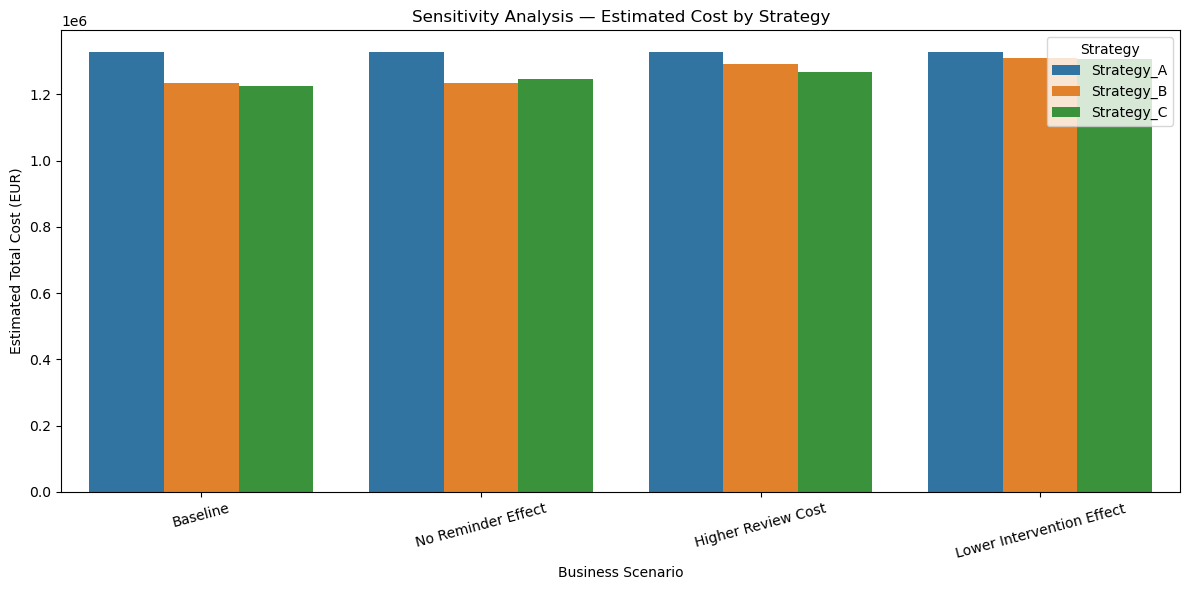

In [106]:

# Prepare data for visualization
sensitivity_plot = sensitivity_results.melt(
    id_vars="Scenario",
    value_vars=["Strategy_A", "Strategy_B", "Strategy_C"],
    var_name="Strategy",
    value_name="Estimated_Cost"
)

# Compare strategy costs across scenarios
plt.figure(figsize=(12, 6))

sns.barplot(
    data=sensitivity_plot,
    x="Scenario",
    y="Estimated_Cost",
    hue="Strategy"
)

plt.title("Sensitivity Analysis — Estimated Cost by Strategy")
plt.xlabel("Business Scenario")
plt.ylabel("Estimated Total Cost (EUR)")
plt.xticks(rotation=15)
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()


**Observation:**

- Strategy C (Tiered Intervention) achieves the lowest estimated cost in three of the four scenarios.
- When automated reminders have no effect, Strategy B (Review All Flagged) becomes the lowest-cost option.
- Higher manual review costs and lower intervention effectiveness reduce the overall cost benefits of intervention strategies.

**Conclusion:** Tiered Intervention shows potential cost advantages, but its effectiveness depends on business assumptions, particularly the impact of automated reminders. These results are hypothetical and do not represent proven financial savings.

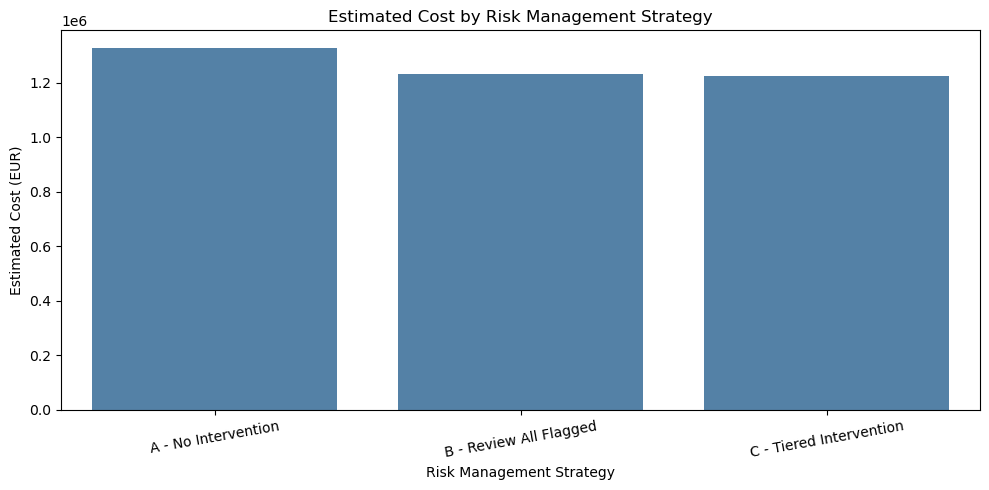

Lowest-cost strategy under these assumptions: C - Tiered Intervention


In [107]:

# Plot estimated total cost by strategy
plt.figure(figsize=(10, 5))

sns.barplot(
    data=strategy_results,
    x="Strategy",
    y="Estimated_Total_Cost",
    color="steelblue"
)

plt.title("Estimated Cost by Risk Management Strategy")
plt.xlabel("Risk Management Strategy")
plt.ylabel("Estimated Cost (EUR)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Identify lowest estimated cost
best_strategy = strategy_results.loc[
    strategy_results["Estimated_Total_Cost"].idxmin(),
    "Strategy"
]

print("Lowest-cost strategy under these assumptions:", best_strategy)


**Observation:**

- Strategy C — Tiered Intervention achieves the lowest estimated cost (€1,226,304), compared with Strategy B (€1,233,440) and Strategy A (€1,327,000).
- Under the hypothetical assumptions, tiered intervention reduces estimated costs by €100,696 compared with no intervention.

**Conclusion:** Risk-based intervention may improve resource allocation and reduce expected costs. However, these results depend on assumed costs and intervention effectiveness, not proven financial savings.

### 6.8 Risk Segmentation & Cost Optimization — Conclusion

Risk segmentation divided customers into Low, Medium, and High risk groups, with observed default rates of 9.37%, 21.77%, and 60.48%, respectively.

The High Risk group represents only 17.25% of customers but contains 47.17% of actual defaults, demonstrating the model's ability to prioritize higher-risk customers.

Under the baseline assumptions, **Strategy C — Tiered Intervention** achieved the lowest estimated cost (€1,226,304), a hypothetical reduction of €100,696 compared with no intervention.

The Sensitivity Analysis showed that Strategy C remained the lowest-cost option in three of four scenarios. However, when automated reminders were assumed to have no effect, Strategy B became more cost-effective.

**Business Conclusion:** Risk segmentation could help banks allocate review resources more efficiently through differentiated interventions. However, the preferred strategy depends on operational costs and intervention effectiveness.

**Limitations:** Risk thresholds, intervention costs, and effectiveness rates are hypothetical. The simulations use historical test data and do not demonstrate actual prevented defaults or proven financial savings.

## Step 7 — Future Work

Although the project achieved its main machine learning objectives, further improvements would be necessary before real-world banking deployment.

### 7.1 Model Improvements

- **Additional Data:** Use more recent and representative customer data to improve generalization.
- **Feature Engineering:** Explore additional repayment trends and credit utilization patterns.
- **Model Optimization:** Further investigate classification thresholds and class imbalance handling using training data.
- **Probability Calibration:** Evaluate whether predicted risk scores accurately reflect observed default probabilities.
- **External Validation:** Test the model on an independent dataset to assess generalization.
- **Fairness Evaluation:** Examine whether model performance and errors differ across demographic groups.

### 7.2 Business and Deployment Improvements

- **Cost-Sensitive Evaluation:** Validate the business simulations using actual financial losses, operational costs, and intervention effectiveness.
- **Risk Segmentation:** Validate Low, Medium, and High risk thresholds using independent data and real operational constraints.
- **Data Engineering Integration:** Develop the planned MySQL database, SQL analysis, BigQuery workflow, and Flask API as part of the wider project.
- **Model Monitoring:** Track predictive performance, data drift, and risk segmentation effectiveness over time.
- **Human Oversight:** Ensure that high-risk predictions are appropriately reviewed before consequential banking decisions.

## Step 8 — Final Project Conclusion

This project demonstrated an end-to-end machine learning approach to predicting credit card default using historical customer data, from data preparation and exploratory analysis to model evaluation and business applications.

Weighted XGBoost was selected as the preferred model because it improved Recall (57.12%) and F1-score (0.5457), allowing more actual default customers to be identified. Feature Importance and SHAP analysis highlighted repayment history as a major contributor to model predictions.

The Business Cost Simulation demonstrated that model selection depends on the relative costs of missed defaults and false alarms. The Risk Review Capacity Simulation showed that reviewing the 500 highest-risk customers identified 361 actual defaults, compared with approximately 111 expected under random selection.

Risk Segmentation further divided customers into Low, Medium, and High risk groups. The High Risk group represented only 17.25% of customers but contained 47.17% of actual defaults. Under the baseline assumptions, Tiered Intervention achieved the lowest simulated cost (€1,226,304). Sensitivity Analysis showed that this advantage was not consistent across all scenarios.

**Overall Conclusion:** The project demonstrates how machine learning can support early credit risk detection, explain predictions, prioritize customer reviews, and inform differentiated risk management strategies.

**Proof of Concept & Real-World Limitations:**

This project is a proof of concept based on a historical public dataset, rather than a production-ready banking solution.

Although the results demonstrate the potential of machine learning for credit risk management, real-world implementation would require more recent and representative customer data, independent validation, probability calibration, and continuous model monitoring.

The business simulations rely on hypothetical financial costs, risk thresholds, and intervention effectiveness. Therefore, the estimated cost reductions do not represent proven financial savings.

Further evaluation of model fairness, regulatory requirements, and human oversight would also be necessary before deployment.

**Final Perspective:** The project provides an experimental foundation for data-driven credit risk management, but its practical effectiveness and financial value must be validated using real banking data and operational conditions.